# Entrega 2 - Análisis Exploratorio

**Grupo:** 10 · Comisión 5K09 (5K09-10)

**Integrantes:**
- Bustelo Nicolás
- Cuello Joaquin
- Lemos Augusto
- Masuet Juan Pablo
- Vazquez Manuel

**Dataset:** OpenAlex - Artículos de Ciencia de Materiales publicados en 2019

## 1. Carga del Dataset desde Google Drive

El archivo ultimo_ok.csv.gz es la salida del pipeline de ingesta (capa Plata enriquecida). Cada fila es un artículo de Ciencia de Materiales publicado en 2019, con las citas acumuladas hasta la descarga, en octubre de 2026.

Además de las columnas que devuelve la API de OpenAlex, la capa Plata agrega variables derivadas (conteos de autores, instituciones, países y referencias, largo del abstract, mes de publicación) y una etapa de enriquecimiento suma información previa al artículo: la trayectoria del primer y del último autor y la de la revista entre 2012 y 2018, el h-index de la institución más destacada y el precio de publicación de la revista.

El diccionario de columnas se calcula a partir del propio dataset: tipo, porcentaje de nulos, cantidad de valores distintos y un ejemplo de cada una.

In [3]:

# ============================================================
# Carga y estructura del dataset OpenAlex (capa Plata enriquecida, DAG v7)
# ============================================================
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Detección de entorno: Google Colab o Local
try:
    from google.colab import drive
    drive.mount("/content/drive")
    CARPETA = Path("/content/drive/MyDrive/FACULTAD/5to AÑO/Ciencia de Datos")
except ImportError:
    CARPETA = Path(".")

# --- Dataset ------------------------------------------------------------
# Busca el archivo tanto en la carpeta local como en Google Drive
candidatos = [
    Path("openalex_silver_enriched.csv"),
    Path("ultimo_ok.csv.gz"),
    Path("ultimo_ok.csv"),
    CARPETA / "openalex_silver_enriched.csv",
    CARPETA / "ultimo_ok.csv.gz",
    CARPETA / "ultimo_ok.csv",
]
ARCHIVO = next((p for p in candidatos if p.exists()), None)
if ARCHIVO is None:
    raise FileNotFoundError(f"No se encontró el dataset en el directorio actual ni en {CARPETA}")

df = pd.read_csv(ARCHIVO, low_memory=False)

# Control: que sea el dataset de Ciencia de Materiales 2019 con la etapa de enriquecimiento
ENRIQUECIDAS = ["first_author_pre_works", "last_author_pre_works", "institution_max_h_index",
                "source_pre_cites_per_work", "source_apc_usd"]
faltan = [c for c in ENRIQUECIDAS if c not in df.columns]
anios = sorted(int(a) for a in df["publication_year"].unique())
if faltan or anios != [2019]:
    raise ValueError(f"{ARCHIVO.name} no es el dataset enriquecido de 2019 "
                     f"(años: {anios}, columnas faltantes: {faltan})")

print(f"Archivo: {ARCHIVO.name}")
print(f"Filas: {df.shape[0]:,}  |  Columnas: {df.shape[1]}")

# Mostrar todas las columnas, recortando el texto largo de cada celda
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 60)

display(df.head())


Archivo: openalex_silver_enriched.csv
Filas: 11,811  |  Columnas: 165


,id,title,cited_by_count,is_top10_percent,authors_count,institutions_count,countries_count,referenced_works_count,domain,field,is_oa,oa_status,apc_paid,source_type,source_is_core,is_in_doaj,funders_count,language,publication_month,abstract_length,abstract,source_pre_works,source_pre_cites,source_pre_cites_per_work,source_apc_usd,first_author_pre_works,first_author_pre_cites,last_author_pre_works,last_author_pre_cites,first_author_country,institution_max_h_index,doi,display_name,relevance_score,publication_year,publication_date,ids_openalex,ids_doi,ids_mag,primary_location_id,primary_location_doi,primary_location_is_oa,primary_location_landing_page_url,primary_location_source_id,primary_location_source_display_name,primary_location_source_issn_l,primary_location_source_issn,primary_location_source_is_oa,primary_location_source_is_in_doaj,primary_location_source_is_core,primary_location_source_listed_in,primary_location_source_host_organization_lineage,primary_location_source_host_organization_lineage_names,primary_location_source_type,primary_location_version,primary_location_is_accepted,primary_location_is_published,primary_location_raw_source_name,primary_location_raw_type,type,indexed_in,indexed_in_count,open_access_is_oa,open_access_oa_status,open_access_any_repository_has_fulltext,authorships,authorships_count,institutions,countries_distinct_count,institutions_distinct_count,corresponding_author_ids,corresponding_author_ids_count,corresponding_institution_ids,corresponding_institution_ids_count,fwci,has_fulltext,citation_normalized_percentile_value,citation_normalized_percentile_is_in_top_1_percent,citation_normalized_percentile_is_in_top_10_percent,cited_by_percentile_year_min,cited_by_percentile_year_max,biblio_issue,biblio_first_page,biblio_last_page,is_retracted,is_paratext,is_xpac,primary_topic_id,primary_topic_display_name,primary_topic_score,primary_topic_subfield_id,primary_topic_subfield_display_name,primary_topic_field_id,primary_topic_field_display_name,primary_topic_domain_id,primary_topic_domain_display_name,topics,topics_count,keywords,keywords_count,concepts,concepts_count,mesh,mesh_count,locations_count,locations,sustainable_development_goals,sustainable_development_goals_count,sustainable_development_goals_aurora,sustainable_development_goals_aurora_count,study_designs,study_designs_count,awards,awards_count,funders,has_content_grobid_xml,has_content_pdf,referenced_works,related_works,related_works_count,counts_by_year,counts_by_year_count,updated_date,created_date,primary_location_pdf_url,primary_location_source_host_organization,primary_location_source_host_organization_name,primary_location_license,primary_location_license_id,open_access_oa_url,apc_list_value,apc_list_currency,apc_list_value_usd,apc_paid_value,apc_paid_currency,apc_paid_value_usd,biblio_volume,best_oa_location_id,best_oa_location_doi,best_oa_location_is_oa,best_oa_location_landing_page_url,best_oa_location_pdf_url,best_oa_location_source_id,best_oa_location_source_display_name,best_oa_location_source_issn_l,best_oa_location_source_issn,best_oa_location_source_is_oa,best_oa_location_source_is_in_doaj,best_oa_location_source_is_core,best_oa_location_source_listed_in,best_oa_location_source_host_organization,best_oa_location_source_host_organization_name,best_oa_location_source_host_organization_lineage,best_oa_location_source_host_organization_lineage_names,best_oa_location_source_type,best_oa_location_license,best_oa_location_license_id,best_oa_location_version,best_oa_location_is_accepted,best_oa_location_is_published,best_oa_location_raw_source_name,best_oa_location_raw_type,content_urls_pdf,content_urls_grobid_xml,ids_pmid
0,W3162828358,Рroduction of 70%Cu–30%Fe alloy by SHS metallurgy and el...,1,False,5,3,1,17,Physical Sciences,Materials Science,False,closed,False,journal,False,False,0,en,6,264,The influence of different methods used to produce Fe–Cu...,248.0,400.0,1.612903,NaN,8.0,14.0,35.0,272.0,RU,720.0,https://doi.org/10.17073/1

In [4]:
# --- Diccionario de columnas -------------------------------------------
# Se arma desde el propio dataset: tipo, % de nulos, valores distintos y un ejemplo
def ejemplo(serie):
    valores = serie.dropna()
    return str(valores.iloc[0])[:60] if len(valores) else None

diccionario = pd.DataFrame({
    "tipo":              df.dtypes.astype(str),
    "% nulos":           (df.isna().mean() * 100).round(2),
    "valores distintos": df.nunique(),
    "ejemplo":           [ejemplo(df[c]) for c in df.columns],
})
display(diccionario)

,tipo,% nulos,valores distintos,ejemplo
id,str,0.00,11811,W3162828358
title,str,0.01,11794,Рroduction of 70%Cu–30%Fe alloy by SHS metallurgy and el...
cited_by_count,int64,0.00,337,1
is_top10_percent,bool,0.00,2,False
authors_count,int64,0.00,28,5
institutions_count,int64,0.00,20,3
countries_count,int64,0.00,8,1
referenced_works_count,int64,0.00,247,17
domain,str,0.00,1,Physical Sciences
field,str,0.00,1,Materials Science


## 2. Chequeo inicial de calidad del dataset

In [5]:
# ============================================================
# Chequeo inicial de calidad del dataset
# ============================================================
CLAVE = "id"                     # identificador único de cada artículo
OBJETIVO = "is_top10_percent"    # target binario (top 10% de su campo y año)
OBJETIVO_NUM = "cited_by_count"  # target numérico (citas)
IDENTIFICADORES = ["ids_mag"]    # numéricas, pero son códigos y no cantidades

def titulo(texto):
    print(f"\n{'=' * 70}\n{texto}\n{'=' * 70}")

# 1. Tamaño
titulo("1. TAMAÑO")
print(f"Filas: {df.shape[0]:,}  |  Columnas: {df.shape[1]}")
print("Cada fila es un artículo de Ciencia de Materiales publicado en 2019 (OpenAlex),")
print("con las citas acumuladas hasta la descarga (octubre de 2026).")

# 2. Tipos
titulo("2. TIPOS DE DATO")
display(df.dtypes.astype(str).value_counts().to_frame("columnas"))

# Columnas de texto que en realidad son booleanas o numéricas
texto = df.select_dtypes(exclude=["number", "bool"]).columns
booleanas_con_nulos = [c for c in texto
                       if set(df[c].dropna().astype(str).unique()) <= {"True", "False"}
                       and df[c].isna().any()]
parecen_numericas = [c for c in texto if c not in booleanas_con_nulos
                     and pd.to_numeric(df[c].dropna(), errors="coerce").notna().mean() > 0.95]
print(f"Booleanas leídas como texto por tener nulos ({len(booleanas_con_nulos)}): {booleanas_con_nulos}")
print(f"Texto que parece numérico ({len(parecen_numericas)}): {parecen_numericas}")

# 3. Nulos por columna
titulo("3. NULOS POR COLUMNA (top 20)")
nulos = df.isna().mean().sort_values(ascending=False)
display((nulos.head(20) * 100).round(2).to_frame("% nulos"))
print(f"Columnas sin ningún nulo: {(nulos == 0).sum()} de {df.shape[1]}")

# 4. Nulos que se explican por otra columna (nulos estructurales)
titulo("4. NULOS ESTRUCTURALES (se explican por el valor de otra columna)")
explicaciones = [
    ("best_oa_location_id",     "no es de acceso abierto (is_oa = False)", df["is_oa"] == False),
    ("apc_paid_value_usd",      "no pagó APC (apc_paid = False)",          df["apc_paid"] == False),
    ("source_is_core",          "sin fuente identificada",                 df["source_type"].isna()),
    ("institution_max_h_index", "sin instituciones (institutions_count = 0)", df["institutions_count"] == 0),
    ("last_author_pre_works",   "uno o ningún autor (authors_count <= 1)", df["authors_count"] <= 1),
]
display(pd.DataFrame([{
    "columna":                  col,
    "% nulos":                  round(df[col].isna().mean() * 100, 2),
    "condición":                condicion,
    "% de los nulos explicados": round(mascara[df[col].isna()].mean() * 100, 1),
} for col, condicion, mascara in explicaciones]).set_index("columna"))

# 5. Columnas sin información
titulo("5. COLUMNAS CONSTANTES (<= 1 valor distinto)")
constantes = df.columns[df.nunique() <= 1]
display(pd.DataFrame({
    "valor":    [df[c].dropna().unique()[0] if df[c].notna().any() else None for c in constantes],
    "% nulos":  [round(df[c].isna().mean() * 100, 2) for c in constantes],
}, index=constantes))

# 6. Duplicados de la clave
titulo(f"6. DUPLICADOS DE LA CLAVE ('{CLAVE}')")
print(f"IDs duplicados: {df[CLAVE].duplicated().sum()}")

# 7. Distribución del objetivo
titulo("7. DISTRIBUCIÓN DEL OBJETIVO")
print(f"'{OBJETIVO}' (proporción, incluye nulos):")
display(df[OBJETIVO].value_counts(normalize=True, dropna=False).round(4).to_frame("proporción"))
print(f"'{OBJETIVO_NUM}': {(df[OBJETIVO_NUM] == 0).mean():.1%} de artículos sin citas  |  "
      f"mediana {df[OBJETIVO_NUM].median():.0f}  |  media {df[OBJETIVO_NUM].mean():.2f}  |  "
      f"máximo {df[OBJETIVO_NUM].max():,}")

# 8. Asimetría de las numéricas (sin identificadores ni constantes)
titulo("8. ASIMETRÍA DE LAS NUMÉRICAS")
numericas = df.select_dtypes("number").columns.difference(IDENTIFICADORES).difference(constantes)
asimetria = df[numericas].skew().sort_values(ascending=False)
display(asimetria.round(2).to_frame("asimetría"))
print(f"Cola larga (asimetría > 2): {list(asimetria[asimetria > 2].index)}")


1. TAMAÑO
Filas: 11,811  |  Columnas: 165
Cada fila es un artículo de Ciencia de Materiales publicado en 2019 (OpenAlex),
con las citas acumuladas hasta la descarga (octubre de 2026).

2. TIPOS DE DATO


,columnas
str,92
int64,26
float64,20
bool,15
object,12


Booleanas leídas como texto por tener nulos (12): ['source_is_core', 'is_in_doaj', 'primary_location_source_is_oa', 'primary_location_source_is_in_doaj', 'primary_location_source_is_core', 'open_access_any_repository_has_fulltext', 'best_oa_location_is_oa', 'best_oa_location_source_is_oa', 'best_oa_location_source_is_in_doaj', 'best_oa_location_source_is_core', 'best_oa_location_is_accepted', 'best_oa_location_is_published']
Texto que parece numérico (4): ['biblio_issue', 'biblio_first_page', 'biblio_last_page', 'biblio_volume']

3. NULOS POR COLUMNA (top 20)


,% nulos
apc_paid_value_usd,79.64
apc_paid_value,79.64
apc_paid_currency,79.64
ids_pmid,72.30
primary_location_license,68.46
primary_location_license_id,68.46
best_oa_location_license,64.80
best_oa_location_license_id,64.80
primary_location_pdf_url,64.24
content_urls_grobid_xml,63.20


Columnas sin ningún nulo: 84 de 165

4. NULOS ESTRUCTURALES (se explican por el valor de otra columna)


...


6. DUPLICADOS DE LA CLAVE ('id')
IDs duplicados: 0

7. DISTRIBUCIÓN DEL OBJETIVO
'is_top10_percent' (proporción, incluye nulos):


,proporción
is_top10_percent,
False,0.8932
True,0.1068


'cited_by_count': 18.3% de artículos sin citas  |  mediana 10  |  media 26.51  |  máximo 2,625

8. ASIMETRÍA DE LAS NUMÉRICAS


,asimetría
apc_list_value,54.47
apc_paid_value,38.53
study_designs_count,32.73
first_author_pre_works,29.07
locations_count,19.12
first_author_pre_cites,15.74
source_pre_works,15.34
cited_by_count,12.17
fwci,11.19
source_pre_cites,8.92


Cola larga (asimetría > 2): ['apc_list_value', 'apc_paid_value', 'study_designs_count', 'first_author_pre_works', 'locations_count', 'first_author_pre_cites', 'source_pre_works', 'cited_by_count', 'fwci', 'source_pre_cites', 'last_author_pre_cites', 'abstract_length', 'last_author_pre_works', 'awards_count', 'mesh_count', 'referenced_works_count', 'corresponding_author_ids_count', 'sustainable_development_goals_count']


In [6]:
# ============================================================
# Duplicados de contenido y valores sospechosos
# ============================================================
es_revista = df["source_type"] == "journal"
materials_project = df["title"].str.contains("by Materials Project", na=False)

# 9. El mismo trabajo cargado con distinto id
titulo("9. DUPLICADOS DE CONTENIDO (mismo DOI o mismo título, distinto id)")
doi_repetido = df["doi"].notna() & df["doi"].duplicated(keep=False)
titulo_repetido = df["title"].duplicated(keep=False)
print(f"Filas con DOI repetido: {doi_repetido.sum()}")
print(f"Filas con título repetido: {titulo_repetido.sum()}  "
      f"(de ellas, {(titulo_repetido & materials_project).sum()} son fichas del Materials Project)")
display(df.loc[(doi_repetido | titulo_repetido) & ~materials_project,
               ["id", "title", "doi", "source_type", "primary_location_source_display_name", "cited_by_count"]]
          .sort_values("title"))

# 10. Valores que indican metadatos incompletos o registros que no son artículos
titulo("10. VALORES SOSPECHOSOS")
abstract_repetido = df["abstract"].duplicated(keep=False)
sospechosos = {
    "Fecha 2019-01-01 (probablemente sólo se conocía el año)": df["publication_date"] == "2019-01-01",
    "Sin autores (authors_count = 0)":                         df["authors_count"] == 0,
    "Sin instituciones (institutions_count = 0)":              df["institutions_count"] == 0,
    "Sin referencias (referenced_works_count = 0)":            df["referenced_works_count"] == 0,
    "Ficha del Materials Project ('Materials Data on ...')":   materials_project,
    "Abstract repetido en más de un artículo":                 abstract_repetido,
    "Idioma detectado 'lv' (letón)":                           df["language"] == "lv",
}
display(pd.DataFrame([{
    "caso":                    caso,
    "artículos":               mascara.sum(),
    "% del total":             round(mascara.mean() * 100, 1),
    "de ellos, en revistas":   (mascara & es_revista).sum(),
} for caso, mascara in sospechosos.items()]).set_index("caso"))

print("Abstracts más repetidos (primeros 80 caracteres):")
display(df.loc[abstract_repetido, "abstract"].str[:80].value_counts().head(8).to_frame("artículos"))

print("Ejemplos de títulos con idioma 'lv':")
display(df.loc[df["language"] == "lv", ["title", "primary_location_source_display_name"]].head(5))


9. DUPLICADOS DE CONTENIDO (mismo DOI o mismo título, distinto id)
Filas con DOI repetido: 0
Filas con título repetido: 32  (de ellas, 2 son fichas del Materials Project)


,id,title,doi,source_type,primary_location_source_display_name,cited_by_count
709,W4242666361,A Supported Nickel Catalyst Stabilized by a Surface Digg...,https://doi.org/10.1002/ange.201912785,journal,Angewandte Chemie,22
5928,W2984237576,A Supported Nickel Catalyst Stabilized by a Surface Digg...,https://doi.org/10.1002/anie.201912785,journal,Angewandte Chemie International Edition,103
1510,W2933923044,A Universal Strategy for Activating the Multicolor Room‐...,https://doi.org/10.1002/anie.201814629,journal,Angewandte Chemie International Edition,469
4858,W4232296220,A Universal Strategy for Activating the Multicolor Room‐...,https://doi.org/10.1002/ange.201814629,journal,Angewandte Chemie,96
9200,W2988467698,Au130−xAgx Nanoclusters with Non‐Metallicity: A Drum of ...,https://doi.org/10.1002/anie.201908694,journal,Angewandte Chemie International Edition,39
7718,W4213128145,Au130−xAgx Nanoclusters with Non‐Metallicity: A Drum of ...,https://doi.org/10.1002/ange.201908694,journal,Angewandte Chemie,14
90,W3098310117,Controlled irradiation hardening of tungsten by cyclic r...,NaN,repository,TU/e Research Portal,4
9974,W2963423156,Controlled irradiation hardening of tungsten by cyclic r...,https://doi.org/10.1088/1361-651x/ab1eec,journal,Modelling and Simulation in Materials Science and Engine...,8
4514,W4235086825,Crosslinkable‐Chitosan‐Enabled Moisture‐Resistant Multil...,https://doi.org/10.1002/marc.201970013,journal,Macromolecular Rapid Communications,8
10716,W2914575087,Crosslinkable‐Chitosan‐Enabled Moisture‐Resistant Multil...,https://doi.org/10.1002/marc.201800853,journal,Macromolecular Rapid Communications,28



10. VALORES SOSPECHOSOS


,artículos,% del total,"de ellos, en revistas"
caso,,,
Fecha 2019-01-01 (probablemente sólo se conocía el año),2358,20.0,1723
Sin autores (authors_count = 0),105,0.9,92
Sin instituciones (institutions_count = 0),1723,14.6,830
Sin referencias (referenced_works_count = 0),2276,19.3,1186
Ficha del Materials Project ('Materials Data on ...'),337,2.9,0
Abstract repetido en más de un artículo,225,1.9,37
Idioma detectado 'lv' (letón),106,0.9,106


Abstracts más repetidos (primeros 80 caracteres):


,artículos
abstract,
Computed materials data using density functional theory calculations. These calc,153
Abstract not provided.,19
"FIZIKO-HIMIČESKIE ASPEKTY IZUČENIÂ KLASTEROV, NANOSTRUKTUR I NANOMATERIALOV МЕЖВ",8
83.080.20,6
-,6
Abstract,5
.,4
補正完畢,4


Ejemplos de títulos con idioma 'lv':


,title,primary_location_source_display_name
70,Universal relationship between low-energy antiferromagne...,Physical review. B./Physical review. B
93,Electronic structure and anomalous Hall effect in the fe...,Physical review. B./Physical review. B
170,Infrared spectroscopic measurements of structural transi...,Physical review. B./Physical review. B
415,Metamagnetic transitions and magnetoelectric coupling in...,Physical review. B./Physical review. B
517,Lattice vibrations of γ - and β -coronene from Raman mic...,Physical Review Materials


### Hallazgos del chequeo de calidad

**1. Tamaño y tipos.** El dataset tiene 11.813 artículos y 163 columnas. Doce columnas booleanas se leen como texto porque tienen nulos: se convierten a True/False antes de analizarlas. Las cuatro columnas biblio_* (volumen, número y páginas) son números guardados como texto y no se usan en el análisis.

**2. Nulos.** 86 de las 163 columnas no tienen nulos. Las que más nulos tienen son, en su mayoría, **nulos estructurales**: no indican un dato perdido, sino que la característica no corresponde a ese artículo.

| Columnas | % nulos | Por qué faltan |
|---|---|---|
| best_oa_location_* | 44 a 65 | El 100 % de los nulos son artículos cerrados, que no tienen una versión abierta. |
| apc_paid_* | 79,2 | Coinciden exactamente con los artículos sin APC pagado (apc_paid = False). |
| institution_max_h_index | 15,2 | Coinciden exactamente con los artículos sin instituciones registradas. |
| last_author_pre_* | 14,9 | El 78 % son artículos con uno o ningún autor; el resto, últimos autores sin historial en OpenAlex. |
| ids_pmid | 72,1 | PubMed indexa sobre todo biomedicina, así que la mayoría de los artículos de materiales no figura (en Medicina 2023 faltaba en el 44 %). |
| Licencias y URL de PDF | 61 a 68 | Sólo existen cuando hay una versión abierta con licencia o PDF declarado. |

En estos casos el nulo tiene un significado (0, False o "no corresponde") y se trata como tal, en lugar de descartar el artículo.

**3. Columnas constantes.** Catorce columnas tienen un único valor. La mayoría se debe a los filtros de la descarga (año, tipo, campo, dominio y no retractados). topics_count vale siempre 3 e institutions está siempre vacía, porque las instituciones vienen dentro de authorships. Ninguna aporta información.

**4. Clave y variables objetivo.** No hay IDs duplicados. is_top10_percent es verdadero en el 10,5 % de los artículos, cerca del 10 % que implica su definición. Las citas tienen una mediana de 10, una media de 26,61 y un máximo de 1.722, y el 19,1 % de los artículos no tiene citas. Con casi siete años de exposición, la distribución es mucho menos extrema que en la muestra de Medicina 2023 (asimetría de 11,05 contra 38,7, y 19,1 % sin citas contra 32,2 %), pero sigue teniendo cola larga.

**5. El mismo trabajo con distinto ID.** La clave es única, pero hay trabajos cargados dos veces: 49 filas comparten título y 4 comparten DOI. Fuera de las fichas del Materials Project, los casos son:

- **Ediciones paralelas de una revista.** Angewandte Chemie publica cada artículo en su edición internacional (DOI 10.1002/anie) y en la alemana (DOI 10.1002/ange). Hay 7 pares en la muestra, y la edición alemana recibe muchas menos citas (por ejemplo, 26 contra 319). La edición alemana aparece en 59 artículos en total, en su mayoría sin su par.
- **Copia en revista y en repositorio.** Por ejemplo, un artículo del International Journal of Nanomedicine con 99 citas y su copia en DOAJ con 1.
- **El mismo DOI en dos idiomas** (inglés y croata, o dos transcripciones de un título en ruso).
- **Registros con el mismo título que el artículo** pero otro DOI de la misma revista, probablemente portadas del número o erratas.

Dentro de las revistas quedan 13 títulos repetidos (26 filas). Se decide qué registro conservar al definir la población.

**6. Valores sospechosos.**

| Caso | Artículos | En revistas | Qué implica |
|---|---|---|---|
| Fecha 2019-01-01 | 2.329 (19,7 %) | 1.653 | Probablemente sólo se conocía el año. El mes 1 queda inflado (25,1 % de los artículos) y publication_month pierde confiabilidad. |
| Sin autores | 120 (1,0 %) | 105 | Error de metadatos: se excluyen de la población. |
| Sin instituciones | 1.801 (15,2 %) | 843 | Metadatos incompletos, no ausencia real. |
| Sin referencias | 2.239 (19,0 %) | 1.119 | Metadatos incompletos. Conviene marcarlos con un indicador. |
| Fichas del Materials Project | 366 (3,1 %) | 0 | Fichas de una base de datos de cálculos, no artículos. Todas están en repositorio y tienen 0 citas. |
| Abstract repetido | 300 (2,5 %) | 78 | Son 36 textos genéricos: las fichas del Materials Project, "Abstract not provided.", textos institucionales de editoriales, "International audience" y uno con la codificación rota. En esos artículos, abstract_length no mide un abstract. |
| Idioma "lv" (letón) | 118 (1,0 %) | 118 | Error de detección: 113 son de revistas de la familia Physical Review, con títulos en inglés. Se recodifican como "en". |

La mayoría de los registros que no son artículos (fichas del Materials Project, copias en repositorio) desaparece al conservar sólo los publicados en revistas. Los metadatos incompletos (sin instituciones, sin referencias, fechas imputadas) siguen presentes también en las revistas y se tratan como una limitación.

### Descarte de columnas

Se descartan dos grupos de columnas:

1. **Constantes (14).** Tienen un único valor en todo el dataset (punto 5 del chequeo), así que no distinguen a ningún artículo.
2. **Con más de 30 % de nulos (36).** En su mayoría son URL, licencias, ISSN y los datos de la mejor versión abierta (best_oa_location_*). Estas últimas repiten información que ya resume oa_status, y sus nulos son los artículos cerrados.

Antes de descartar ids_pmid se crea el indicador in_pubmed (si el artículo está indexado en PubMed). No se crea un indicador de licencia abierta porque casi coincide con el tipo de acceso: ningún artículo closed o bronze la tiene, y la tienen el 94 % de los gold y el 100 % de los hybrid. Repetiría lo que ya dice oa_status.

Se protegen las columnas que agregan la capa Plata y la etapa de enriquecimiento. Sólo una supera el umbral: **source_apc_usd** (48,9 % de nulos), el precio actual de publicar en la revista. Sus nulos no son un dato perdido al azar: faltan en el 98,5 % de los artículos diamond, que no cobran por publicar, y en la mitad de los closed. Se conserva para evaluar si el costo de publicación se asocia con las citas. En cambio, apc_list_value_usd, que mide algo parecido, se descarta: tiene casi los mismos nulos y no coincide con source_apc_usd en el 77 % de las filas que tienen los dos datos.

Resultado: de 164 columnas (las 163 del archivo más in_pubmed) quedan 114.

In [7]:
# ============================================================
# Descarte de columnas constantes y con demasiados valores nulos
# ============================================================
UMBRAL_NULOS = 30   # % máximo de nulos permitido; las columnas por encima se descartan

# Columnas que se conservan aunque superen el umbral: las que agregan la capa Plata
# y la etapa de enriquecimiento, pensadas para el análisis
PROTEGIDAS = [
    # Capa Plata
    "id", "title", "cited_by_count", "is_top10_percent",
    "authors_count", "institutions_count", "countries_count", "referenced_works_count",
    "is_oa", "oa_status", "apc_paid", "source_type", "source_is_core", "is_in_doaj",
    "funders_count", "language", "publication_month", "abstract_length", "abstract",
    # Enriquecimiento (historia previa a 2019 y datos de la revista)
    "source_pre_works", "source_pre_cites", "source_pre_cites_per_work", "source_apc_usd",
    "first_author_pre_works", "first_author_pre_cites",
    "last_author_pre_works", "last_author_pre_cites",
    "first_author_country", "institution_max_h_index",
]

# Antes de descartar: indicadores que resumen lo que significa el nulo
df["in_pubmed"] = df["ids_pmid"].notna()          # indexado en PubMed (sí/no)

# 1. Constantes: se descartan siempre, porque no distinguen a ningún artículo
constantes = df.columns[df.nunique() <= 1]

# 2. Demasiados nulos: se descartan salvo las protegidas
nulos = df.isna().mean().mul(100).round(2)
superan = nulos[nulos > UMBRAL_NULOS]

resumen = pd.DataFrame({"% nulos": nulos[constantes.union(superan.index)]})
resumen["motivo"] = ["constante" if c in constantes else f"más de {UMBRAL_NULOS} % de nulos"
                     for c in resumen.index]
resumen["decisión"] = ["se conserva (protegida)" if c in PROTEGIDAS and c not in constantes
                       else "se descarta" for c in resumen.index]
resumen = resumen.sort_values(["decisión", "motivo", "% nulos"], ascending=[False, True, False])
display(resumen)

a_descartar = resumen.index[resumen["decisión"] == "se descarta"]
columnas_antes = df.shape[1]
df = df.drop(columns=a_descartar)

print(f"Umbral: {UMBRAL_NULOS}% de nulos")
print(f"Descartadas: {(resumen.loc[a_descartar, 'motivo'] == 'constante').sum()} constantes y "
      f"{(resumen.loc[a_descartar, 'motivo'] != 'constante').sum()} por nulos")
print(f"Columnas: {columnas_antes} -> {df.shape[1]}  ({len(a_descartar)} descartadas)")

,% nulos,motivo,decisión
best_oa_location_is_oa,43.28,constante,se descarta
domain,0.00,constante,se descarta
field,0.00,constante,se descarta
institutions,0.00,constante,se descarta
is_paratext,0.00,constante,se descarta
is_retracted,0.00,constante,se descarta
is_xpac,0.00,constante,se descarta
primary_topic_domain_display_name,0.00,constante,se descarta
primary_topic_domain_id,0.00,constante,se descarta
primary_topic_field_display_name,0.00,constante,se descarta


Umbral: 30% de nulos
Descartadas: 14 constantes y 37 por nulos
Columnas: 166 -> 115  (51 descartadas)


## 3. Población de análisis

La unidad de estudio es el **artículo científico del campo de la Ciencia de Materiales**. La población se define en dos etapas.

**1. Filtros aplicados en el pipeline de ingesta (API de OpenAlex).** Se consultan los trabajos que cumplen las cinco condiciones siguientes:

| Condición | Filtro de la API |
|---|---|
| Publicado en 2019 | publication_year:2019 |
| Con abstract disponible | has_abstract:true |
| De tipo artículo | type:article |
| No retractado | is_retracted:false |
| Cuyo tema principal pertenece al campo Materials Science (dominio Physical Sciences) | primary_topic.field.id:25 |

El campo se determina a partir del tema principal que OpenAlex asigna a cada artículo. Se eligió un único campo para que los artículos sean comparables entre sí: el volumen de citas varía mucho entre disciplinas, y mezclar campos haría que la temática pesara más que cualquier otro factor. El año 2019 da casi siete años de exposición a citas hasta la descarga: con artículos recientes, como los de Medicina 2023 que se usaron antes, un tercio no tenía citas y la variable objetivo casi no variaba.

Sobre los 107.963 artículos que cumplen esas condiciones se toma una muestra aleatoria reproducible de 12.000 (semilla 42 para los primeros 10.000 y 43 para los 2.000 restantes). La capa Plata elimina los 187 artículos repetidos entre ambos lotes y deja 11.813.

**2. Filtros aplicados en este notebook.** Se excluyen los casos que no representan un artículo publicado en una revista, que no pueden analizarse o que duplican a otro:

1. **Artículos fuera de revistas.** Se conservan sólo los publicados en revistas (source_type igual a "journal"). Se excluyen los depositados en repositorios, que son copias de trabajos y no publicaciones en una revista, las series de libros y los que no tienen una fuente identificada. Entre los excluidos están las 366 fichas del Materials Project, que no son artículos. Fuera de las revistas, la mediana de citas es 0 y el 80 % de los registros no tiene ninguna.
2. **Artículos sin autores.** Un artículo sin autores registrados es un error de los metadatos.
3. **Artículos sin percentil.** Sin el percentil normalizado no puede calcularse la variable objetivo binaria (is_top10_percent). Es un paso de verificación: no tiene nulos, así que debe excluir cero artículos. El dominio y el campo no se verifican acá porque son constantes (sección 2) y se descartaron.
4. **Edición alemana de Angewandte Chemie.** La revista publica cada artículo en su edición internacional y en una edición alemana con otro DOI (10.1002/ange). La edición alemana es una segunda publicación del mismo trabajo y recibe una fracción de las citas: su mediana es de 16 contra 74 de la internacional. Se excluye entera, aunque el artículo original no esté en la muestra, porque sus citas no miden el impacto del trabajo.
5. **Títulos repetidos.** Entre los registros de revista que comparten título se conserva el más citado. En los casos revisados en la sección 2, el registro que se descarta es una portada del número, una errata o el mismo artículo registrado con otro DOI.

Tras estos filtros, la población de análisis queda en **10.326 artículos**.

No se excluyen los artículos con abstract genérico, sin referencias, sin instituciones o con la fecha imputada al 1 de enero. Esos valores indican metadatos incompletos y no ausencia real, pero excluirlos eliminaría una parte importante de la muestra y la sesgaría hacia las revistas más establecidas. Se marcan con cuatro indicadores (abstract_generico, sin_referencias, sin_instituciones y fecha_imputada) para tratarlos como una limitación en las variables que afectan.

In [8]:
# ============================================================
# Población de análisis: embudo de filtrado
# ============================================================
# Marcas de metadatos incompletos. Se calculan sobre el dataset completo, antes de filtrar,
# porque un abstract genérico se reconoce por repetirse en otros registros
df["abstract_generico"] = df["abstract"].duplicated(keep=False)
df["sin_referencias"]   = df["referenced_works_count"] == 0
df["sin_instituciones"] = df["institutions_count"] == 0
df["fecha_imputada"]    = df["publication_date"] == "2019-01-01"

edicion_alemana = df["doi"].str.contains("/ange.", regex=False, na=False)   # Angewandte Chemie (alemana)

filtros = [
    ("Dataset de la capa Plata (muestra de OpenAlex)",   pd.Series(True, index=df.index)),
    ("Publicado en revista (source_type = journal)",     df["source_type"] == "journal"),
    ("Con al menos un autor",                            df["authors_count"] > 0),
    ("Con percentil (is_top10_percent no nulo)",         df["is_top10_percent"].notna()),
    ("Sin la edición alemana de Angewandte Chemie",      ~edicion_alemana),
]

mascara = pd.Series(True, index=df.index)
pasos = []
for nombre, condicion in filtros:
    antes = mascara.sum()
    mascara &= condicion
    pasos.append({"paso": nombre, "quedan": mascara.sum(), "excluidos": antes - mascara.sum()})

# Entre registros con el mismo título se conserva el más citado (el artículo, no la portada).
# Se busca dentro de lo que queda, para no descartar un artículo porque su copia en un
# repositorio era más citada
mas_citado_primero = df[mascara].sort_values("cited_by_count", ascending=False, kind="stable")
titulo_repetido = mas_citado_primero["title"].duplicated().reindex(df.index, fill_value=False)
antes = mascara.sum()
mascara &= ~titulo_repetido
pasos.append({"paso": "Sin títulos repetidos (se conserva el registro más citado)",
              "quedan": mascara.sum(), "excluidos": antes - mascara.sum()})

embudo = pd.DataFrame(pasos)
embudo["% del inicial"] = (embudo["quedan"] / len(df) * 100).round(1)
display(embudo)

# Qué había en lo excluido por fuente
print("Fuentes excluidas en el primer filtro:")
display(df.loc[df["source_type"] != "journal", "source_type"]
          .value_counts(dropna=False).to_frame("artículos"))
print(f"Fichas del Materials Project entre las excluidas por fuente: "
      f"{(df['title'].str.contains('by Materials Project', na=False) & (df['source_type'] != 'journal')).sum()}")

# De acá en adelante, todo el análisis trabaja sobre la población filtrada
df = df[mascara].copy()
print(f"Población de análisis: {len(df):,} artículos")

# Las marcas de metadatos incompletos no excluyen artículos: quedan como limitación
marcas = df[["abstract_generico", "sin_referencias", "sin_instituciones", "fecha_imputada"]]
display(pd.DataFrame({"artículos": marcas.sum(),
                      "% de la población": (marcas.mean() * 100).round(1)}))

,paso,quedan,excluidos,% del inicial
0,Dataset de la capa Plata (muestra de OpenAlex),11811,0,100.0
1,Publicado en revista (source_type = journal),10550,1261,89.3
2,Con al menos un autor,10458,92,88.5
3,Con percentil (is_top10_percent no nulo),10458,0,88.5
4,Sin la edición alemana de Angewandte Chemie,10385,73,87.9
5,Sin títulos repetidos (se conserva el registro más citado),10383,2,87.9


Fuentes excluidas en el primer filtro:


,artículos
source_type,
repository,876
NaN,286
book series,99


Fichas del Materials Project entre las excluidas por fuente: 337
Población de análisis: 10,383 artículos


,artículos,% de la población
abstract_generico,34,0.3
sin_referencias,1140,11.0
sin_instituciones,737,7.1
fecha_imputada,1706,16.4


## 4. Descripción de la población

Esta sección describe los artículos variable por variable, sin relacionarlas todavía con el impacto: cómo se distribuyen las variables numéricas, tanto las del artículo como las de su historia previa, y cómo está compuesta la muestra por tipo de acceso, idioma, subcampo, país y editorial.

Antes se aplican dos correcciones que surgieron del chequeo de calidad: las booleanas leídas como texto se convierten a True/False, y el idioma "lv" se recodifica como "en".

In [9]:
# ============================================================
# Variables para el análisis y conversiones
# ============================================================
# Del artículo: tamaño del trabajo y del texto
NUMERICAS = ["cited_by_count", "authors_count", "institutions_count", "countries_count",
             "referenced_works_count", "funders_count", "abstract_length", "publication_month"]
# Del enriquecimiento: historia previa a 2019 de la revista, los autores y la institución
PREVIAS = ["source_pre_cites_per_work", "source_pre_works", "source_apc_usd",
           "first_author_pre_works", "first_author_pre_cites",
           "last_author_pre_works", "last_author_pre_cites", "institution_max_h_index"]
CATEGORICAS = ["oa_status", "language", "primary_topic_subfield_display_name",
               "first_author_country", "primary_location_source_host_organization_name"]
BOOLEANAS = ["is_top10_percent", "is_oa", "apc_paid", "source_is_core", "is_in_doaj", "in_pubmed"]

# Las booleanas con nulos se leen como texto: las pasamos a True/False reales
for c in BOOLEANAS:
    df[c] = df[c].map({True: True, False: False, "True": True, "False": False})
print("Nulos en las booleanas tras el filtro de población:", df[BOOLEANAS].isna().sum().sum())
df[BOOLEANAS] = df[BOOLEANAS].astype(bool)

# Idioma: 'lv' es un error de detección en títulos en inglés (sección 2)
df["language"] = df["language"].replace({"lv": "en"})

# Transformación logarítmica de las citas, útil por la fuerte asimetría
df["log_citas"] = np.log1p(df["cited_by_count"])

COLOR = "#4C72B0"   # un solo color para los gráficos de una serie
sns.set_theme(style="whitegrid")
print(f"Unidad de estudio: artículo  |  n = {len(df):,}")

Nulos en las booleanas tras el filtro de población: 0
Unidad de estudio: artículo  |  n = 10,383


In [10]:
desc = df[NUMERICAS + PREVIAS].describe(percentiles=[.25, .5, .75, .9, .99]).T
desc["asimetria"] = df[NUMERICAS + PREVIAS].skew()
desc["%_ceros"] = (df[NUMERICAS + PREVIAS] == 0).mean() * 100
desc["%_nulos"] = df[NUMERICAS + PREVIAS].isna().mean() * 100
display(desc.round(2))

,count,mean,std,min,25%,50%,75%,90%,99%,max,asimetria,%_ceros,%_nulos
cited_by_count,10383.0,29.84,63.01,0.0,4.00,13.00,32.00,69.0,260.18,2625.00,11.71,10.52,0.00
authors_count,10383.0,5.29,3.00,1.0,3.00,5.00,7.00,9.0,15.00,38.00,1.34,0.00,0.00
institutions_count,10383.0,2.38,1.90,0.0,1.00,2.00,3.00,5.0,9.00,20.00,1.79,7.10,0.00
countries_count,10383.0,1.25,0.74,0.0,1.00,1.00,1.00,2.0,4.00,7.00,1.74,7.19,0.00
referenced_works_count,10383.0,38.59,36.08,0.0,18.00,36.00,51.00,68.0,179.18,808.00,4.68,10.98,0.00
funders_count,10383.0,1.46,1.75,0.0,0.00,1.00,2.00,4.0,8.00,17.00,1.86,37.87,0.00
abstract_length,10383.0,157.45,86.96,1.0,113.00,156.00,199.00,243.0,363.18,3857.00,9.06,0.00,0.00
publication_month,10383.0,5.75,3.80,1.0,2.00,6.00,9.00,11.0,12.00,12.00,0.19,0.00,0.00
source_pre_cites_per_work,10269.0,34.94,33.14,0.0,9.56,29.97,47.65,74.4,162.51,435.28,1.95,0.91,1.10
source_pre_works,10383.0,17258.63,32616.36,0.0,1090.00,5368.00,17551.00,45583.0,138921.00,351626.00,4.28,1.10,0.00


In [11]:
for c in CATEGORICAS:
    print(f"\n=== {c}  ({df[c].nunique()} categorías, {df[c].isna().mean():.1%} vacíos) ===")
    display(df[c].value_counts(dropna=False).head(10).to_frame("n")
              .assign(pct=lambda t: (t["n"] / len(df) * 100).round(1)))

print("\n=== Booleanas (% True) ===")
display((df[BOOLEANAS].mean() * 100).round(1).to_frame("% True"))


=== oa_status  (6 categorías, 0.0% vacíos) ===


,n,pct
oa_status,,
closed,4585,44.2
gold,1928,18.6
diamond,1395,13.4
green,955,9.2
bronze,831,8.0
hybrid,689,6.6



=== language  (25 categorías, 0.1% vacíos) ===


,n,pct
language,,
en,9949,95.8
ru,85,0.8
id,72,0.7
es,54,0.5
fa,34,0.3
pt,33,0.3
uk,32,0.3
tr,28,0.3
ko,27,0.3



=== primary_topic_subfield_display_name  (8 categorías, 0.0% vacíos) ===


...

,n,pct
first_author_country,,
CN,2719,26.2
NaN,908,8.7
US,898,8.6
RU,585,5.6
IN,559,5.4
JP,491,4.7
DE,376,3.6
KR,304,2.9
IR,233,2.2



=== primary_location_source_host_organization_name  (600 categorías, 9.1% vacíos) ===


,n,pct
primary_location_source_host_organization_name,,
American Chemical Society,1359,13.1
Wiley,1239,11.9
Royal Society of Chemistry,1045,10.1
NaN,944,9.1
Multidisciplinary Digital Publishing Institute,683,6.6
IOP Publishing,433,4.2
Elsevier BV,388,3.7
Pleiades Publishing,337,3.2
Taylor & Francis,331,3.2



=== Booleanas (% True) ===


,% True
is_top10_percent,12.0
is_oa,55.8
apc_paid,23.1
source_is_core,83.4
is_in_doaj,23.4
in_pubmed,31.4


### Composición de la población

- **Citas.** La mediana es 13, la media 30,1 y el máximo 1.722. El 11,0 % de los artículos no tiene citas. La asimetría (10,6) es menor que en Medicina 2023, pero sigue siendo alta, así que se trabaja con log(1 + citas).
- **Escala del trabajo.** Las autorías son chicas: la mediana es de 5 autores, 2 instituciones y 1 país, y el 99 % de los artículos tiene 15 autores o menos. La mediana de referencias es 36. El 38,1 % no declara financiadores.
- **Historia previa (enriquecimiento).** Entre 2012 y 2018, el último autor tiene una mediana de 94 trabajos y 2.585 citas, contra 12 trabajos y 215 citas del primer autor. Coincide con la práctica habitual: el último autor suele ser el jefe del grupo y el primero, un investigador en formación. Estas variables tienen entre 4 % y 9 % de nulos (autores sin historial en OpenAlex o artículos de un solo autor), y source_apc_usd tiene 42,2 %.
- **Composición.** El 95,4 % de los artículos está en inglés y el 53,8 % pertenece al subcampo Materials Chemistry. El primer autor es de China en el 26,4 % de los casos, de Estados Unidos en el 8,2 % y de Rusia en el 5,7 %. Las editoriales principales son la American Chemical Society (13,3 %), Wiley (12,3 %) y la Royal Society of Chemistry (9,8 %). El 84,0 % se publicó en revistas core y el 45,3 % es de acceso cerrado (en Medicina 2023 era el 14,6 %).
- **Categóricas con muchas categorías.** first_author_country tiene 106 países y la editorial tiene 572 valores. Para usarlas en un modelo hay que agrupar las categorías chicas.

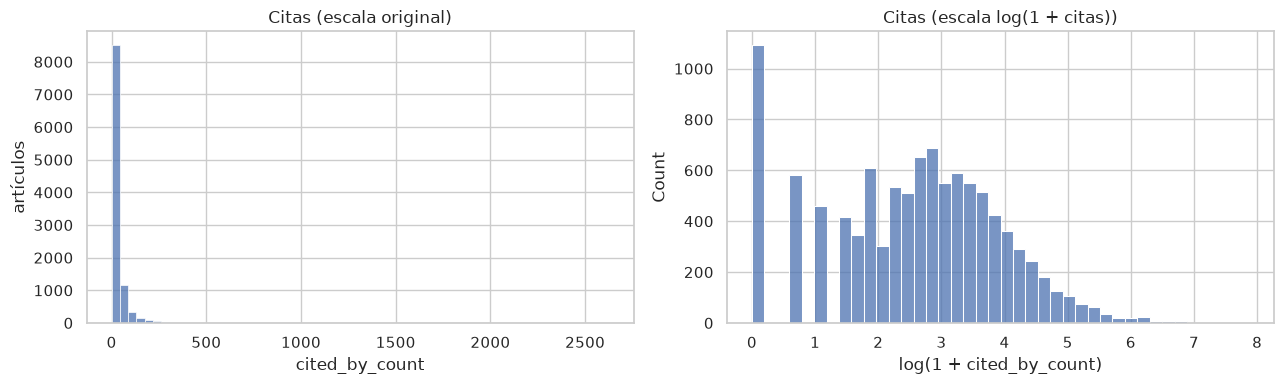

Media: 29.84  |  Mediana: 13  |  Máx: 2625
Sin citas: 10.5%  |  Varianza/media: 133.0
El 1% más citado concentra el 16% de todas las citas


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(df["cited_by_count"], bins=60, color=COLOR, ax=ax[0])
ax[0].set(title="Citas (escala original)", xlabel="cited_by_count", ylabel="artículos")

sns.histplot(df["log_citas"], bins=40, color=COLOR, ax=ax[1])
ax[1].set(title="Citas (escala log(1 + citas))", xlabel="log(1 + cited_by_count)")
plt.tight_layout(); plt.show()

c = df["cited_by_count"]
print(f"Media: {c.mean():.2f}  |  Mediana: {c.median():.0f}  |  Máx: {c.max()}")
print(f"Sin citas: {(c == 0).mean():.1%}  |  Varianza/media: {c.var() / c.mean():.1f}")
top1 = c.nlargest(len(c) // 100).sum() / c.sum()
print(f"El 1% más citado concentra el {top1:.0%} de todas las citas")

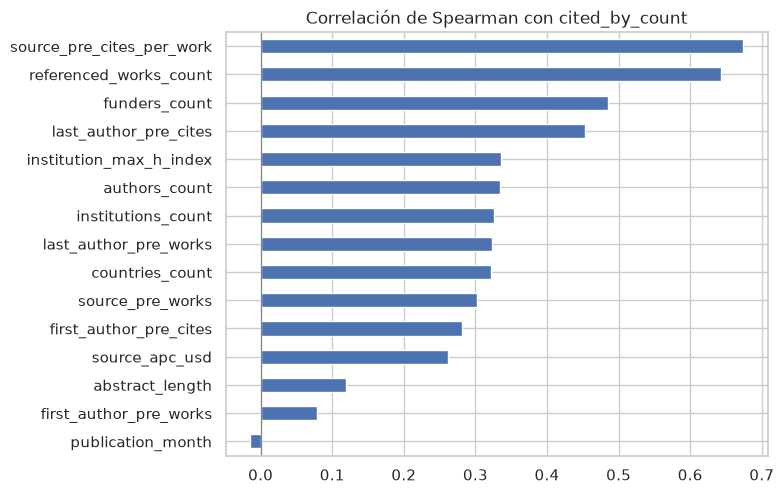

,rho
source_pre_cites_per_work,0.674
referenced_works_count,0.643
funders_count,0.485
last_author_pre_cites,0.453
institution_max_h_index,0.336
authors_count,0.335
institutions_count,0.326
last_author_pre_works,0.323
countries_count,0.322
source_pre_works,0.302


In [13]:
corr = (df[NUMERICAS + PREVIAS].corr(method="spearman")["cited_by_count"]
        .drop("cited_by_count").sort_values())

corr.plot.barh(figsize=(7, 5.5), color=COLOR, title="Correlación de Spearman con cited_by_count")
plt.axvline(0, color="grey", lw=.8); plt.show()
display(corr.sort_values(ascending=False).round(3).to_frame("rho"))

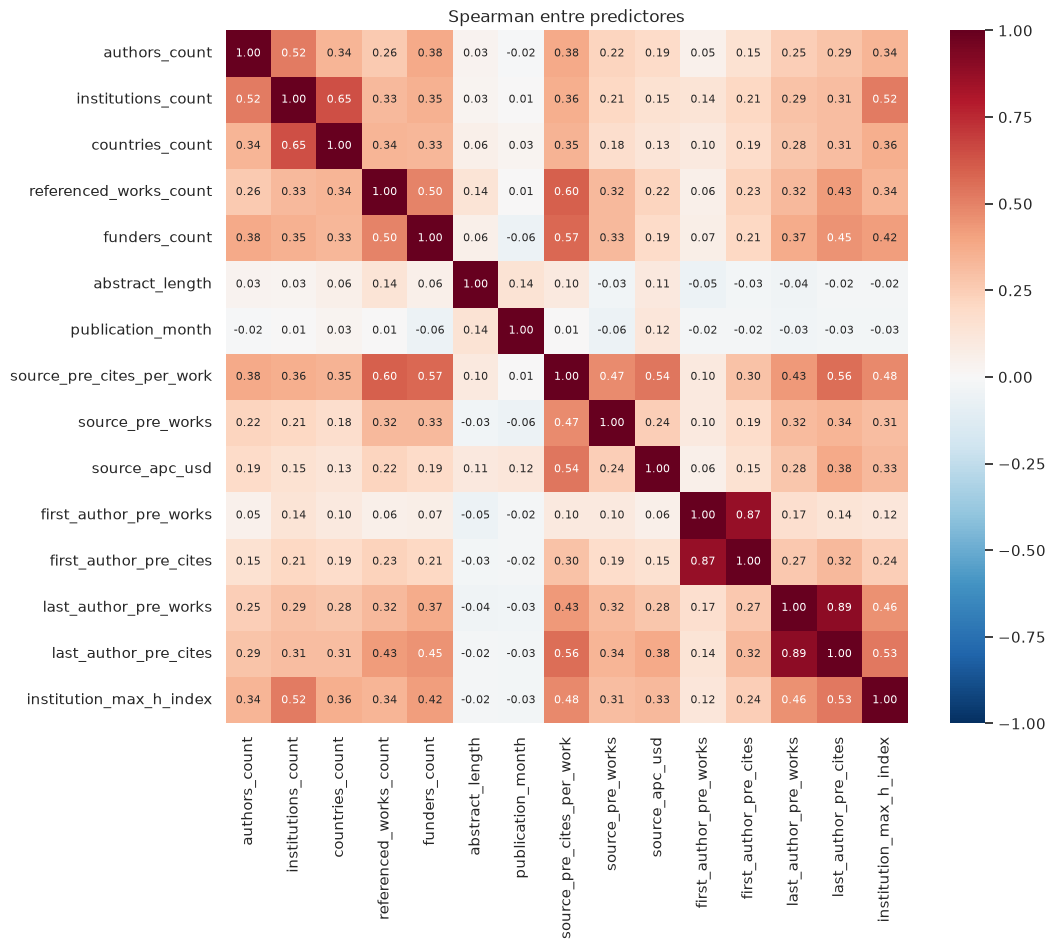

In [14]:
predictores = [c for c in NUMERICAS + PREVIAS if c != "cited_by_count"]
plt.figure(figsize=(11, 9))
sns.heatmap(df[predictores].corr(method="spearman"), annot=True, fmt=".2f",
            cmap="RdBu_r", vmin=-1, vmax=1, annot_kws={"size": 8})
plt.title("Spearman entre predictores"); plt.show()

**Conclusión.** La variable más asociada con las citas es **source_pre_cites_per_work** (ρ = 0,68): el prestigio previo de la revista, medido como las citas por artículo que recibía entre 2012 y 2018. Como se calcula con años anteriores a 2019, no incluye las citas del propio artículo y no es fuga. Le siguen referenced_works_count (0,65), funders_count (0,48) y last_author_pre_cites (0,43).

Del lado de los autores importa el último y no el primero: las citas previas del último autor correlacionan 0,43 con las citas del artículo, las del primero 0,26, y la cantidad de trabajos previos del primero casi no se asocia (0,08). publication_month (−0,01) y abstract_length (0,15) prácticamente no se relacionan con las citas.

Entre los predictores hay cuatro pares que superan el umbral de 0,6 y sugieren redundancia:

- **first_author_pre_works con first_author_pre_cites (0,88) y last_author_pre_works con last_author_pre_cites (0,89).** Para cada autor, los trabajos y las citas previas miden casi lo mismo. Conviene conservar sólo las citas, que se asocian más con el objetivo.
- **institutions_count con countries_count (0,66)**, igual que en Medicina.
- **referenced_works_count con source_pre_cites_per_work (0,61).** Las revistas de más prestigio publican artículos con más bibliografía, o registran mejor sus referencias.

El prestigio de la revista también se asocia con los financiadores (0,57), el precio de publicación (0,52) y las citas previas del último autor (0,53): los grupos consolidados y financiados publican en las revistas de más prestigio. El resto de los pares queda por debajo de 0,6, así que cada variable conserva información propia, aunque varias reflejan en parte una misma dimensión de recursos y prestigio.


=== oa_status ===


,n,mediana,media,pct_cero,pct_top10
oa_status,,,,,
gold,1928,21.5,41.9,1.2,16.0
green,955,19.0,38.4,8.2,15.4
hybrid,689,17.0,34.0,7.5,14.4
closed,4585,15.0,31.7,6.7,13.4
bronze,831,6.0,15.7,21.3,6.5
diamond,1395,2.0,7.5,32.7,1.7



=== is_oa ===


,n,mediana,media,pct_cero,pct_top10
is_oa,,,,,
False,4585,15.0,31.7,6.7,13.4
True,5798,11.0,28.3,13.6,10.9



=== apc_paid ===


...

,n,mediana,media,pct_cero,pct_top10
is_in_doaj,,,,,
True,2430,15.0,35.0,5.8,13.0
False,7953,12.0,28.3,12.0,11.7



=== in_pubmed ===


,n,mediana,media,pct_cero,pct_top10
in_pubmed,,,,,
True,3262,27.0,49.9,0.6,21.5
False,7121,8.0,20.7,15.1,7.7



=== primary_topic_subfield_display_name ===


,n,mediana,media,pct_cero,pct_top10
primary_topic_subfield_display_name,,,,,
Biomaterials,1367,19.0,36.1,9.3,11.5
"Electronic, Optical and Magnetic Materials",1718,14.0,30.8,7.2,11.6
Materials Chemistry,5560,13.0,30.3,10.8,12.8
"Surfaces, Coatings and Films",361,14.0,29.9,7.8,12.5
Polymers and Plastics,1049,10.0,22.8,14.5,9.2
Ceramics and Composites,221,7.0,14.0,15.8,10.4
Metals and Alloys,62,6.0,12.8,12.9,4.8
General Materials Science,45,2.0,6.5,40.0,15.6


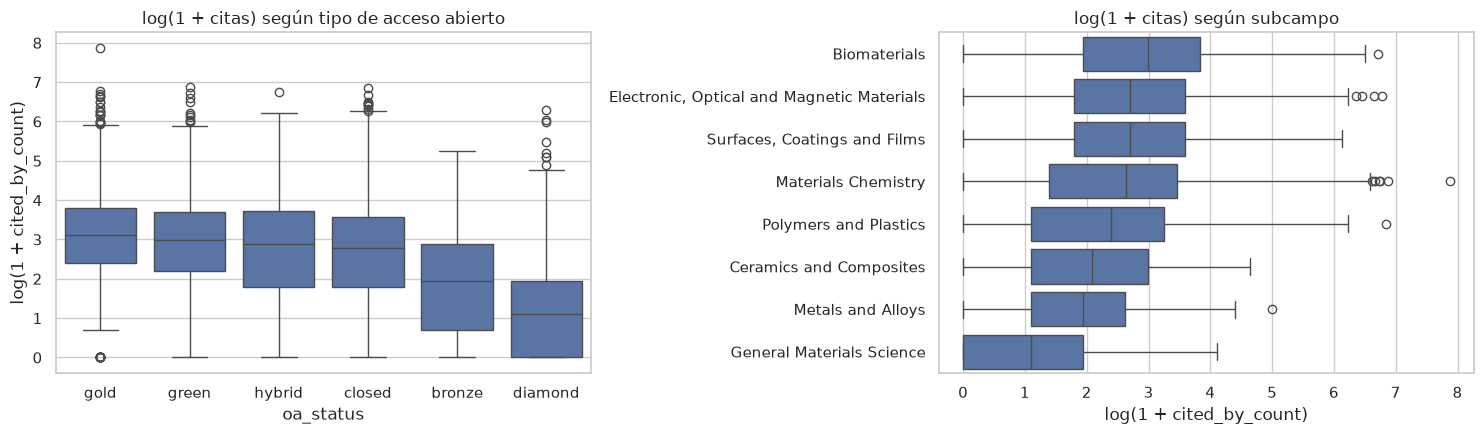

In [15]:
def resumen_por(col):
    return (df.groupby(col, dropna=False)
              .agg(n=("cited_by_count", "size"),
                   mediana=("cited_by_count", "median"),
                   media=("cited_by_count", "mean"),
                   pct_cero=("cited_by_count", lambda s: (s == 0).mean() * 100),
                   pct_top10=("is_top10_percent", lambda s: s.mean() * 100))
              .query("n >= 30").sort_values("media", ascending=False).round(1))

for col in ["oa_status", "is_oa", "apc_paid", "source_is_core", "is_in_doaj", "in_pubmed",
            "primary_topic_subfield_display_name"]:
    print(f"\n=== {col} ===")
    display(resumen_por(col))

orden_oa = df.groupby("oa_status")["log_citas"].median().sort_values(ascending=False).index
orden_sub = (df.groupby("primary_topic_subfield_display_name")["log_citas"].median()
               .sort_values(ascending=False).index)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sns.boxplot(data=df, x="oa_status", y="log_citas", order=orden_oa, color=COLOR, ax=ax[0])
ax[0].set(title="log(1 + citas) según tipo de acceso abierto", xlabel="oa_status",
          ylabel="log(1 + cited_by_count)")
sns.boxplot(data=df, y="primary_topic_subfield_display_name", x="log_citas", order=orden_sub,
            color=COLOR, ax=ax[1])
ax[1].set(title="log(1 + citas) según subcampo", ylabel="", xlabel="log(1 + cited_by_count)")
plt.tight_layout(); plt.show()

### Tipos de acceso abierto (oa_status)

La variable oa_status indica cómo puede leerse gratuitamente un artículo. OpenAlex la asigna con la metodología de Unpaywall, a partir de tres criterios: dónde se encuentra la versión gratuita, quién paga la publicación y bajo qué licencia se distribuye.

| Tipo | Dónde se lee gratis | Pago de los autores | Licencia abierta | Descripción |
|---|---|---|---|---|
| **gold** | En la revista, que es completamente de acceso abierto | Sí, en general mediante un cargo por publicación (APC) | Sí | Revista abierta que cobra a los autores por publicar |
| **diamond** | En la revista, que es completamente de acceso abierto | No | Sí | Revista abierta y gratuita para autores y lectores, sostenida por universidades o sociedades científicas |
| **hybrid** | En la revista, que es de suscripción, pero este artículo fue liberado | Sí, mediante un APC | Sí | Revista paga en la que el autor pagó para que su artículo sea abierto |
| **bronze** | En el sitio de la revista | No | No | La editorial lo muestra gratis sin licencia abierta, por lo que puede volver a restringir el acceso |
| **green** | En un repositorio, no en la revista | No | Depende del repositorio | El artículo está cerrado en la revista, pero existe una copia gratuita en otro sitio |
| **closed** | En ningún sitio | No corresponde | No corresponde | Sólo accesible mediante suscripción |

**Criterio de asignación.** Un artículo puede tener varias versiones gratuitas a la vez. OpenAlex le asigna la de mayor prioridad, en este orden: gold y diamond, hybrid, bronze, green y, por último, closed. Por lo tanto, green indica que el único acceso gratuito disponible es un repositorio.

**Relación con otras variables del dataset.**

1. **is_oa** es verdadero en todos los tipos excepto closed.
2. **apc_paid** (se registró un pago por publicar) es verdadero en el 99,9 % de los gold y en el 70,5 % de los hybrid, y prácticamente nulo en el resto.
3. **is_in_doaj** (la revista figura en el Directory of Open Access Journals) es verdadero en el 81 % de los gold, pero sólo en el 29,5 % de los diamond: muchas revistas diamond de la muestra no están en DOAJ.

**Qué muestra la tabla.** Gold, green e hybrid tienen las medianas más altas (21, 18 y 18,5 citas), seguidos de closed (14). Bronze (5) y diamond (2) quedan muy por debajo, y el 34,1 % de los diamond no tiene citas. Por eso **is_oa invierte el resultado de Medicina 2023**: los abiertos tienen una mediana de 11 citas y los cerrados de 14, porque el grupo de los abiertos incluye a los diamond y bronze.

**Observación sobre la población.** En Ciencia de Materiales el acceso cerrado es mucho más común que en Medicina (45,3 % contra 14,6 %). Los green son artículos de revistas de suscripción con una copia en un repositorio; sus editoriales principales son la American Chemical Society, la American Physical Society y Wiley.

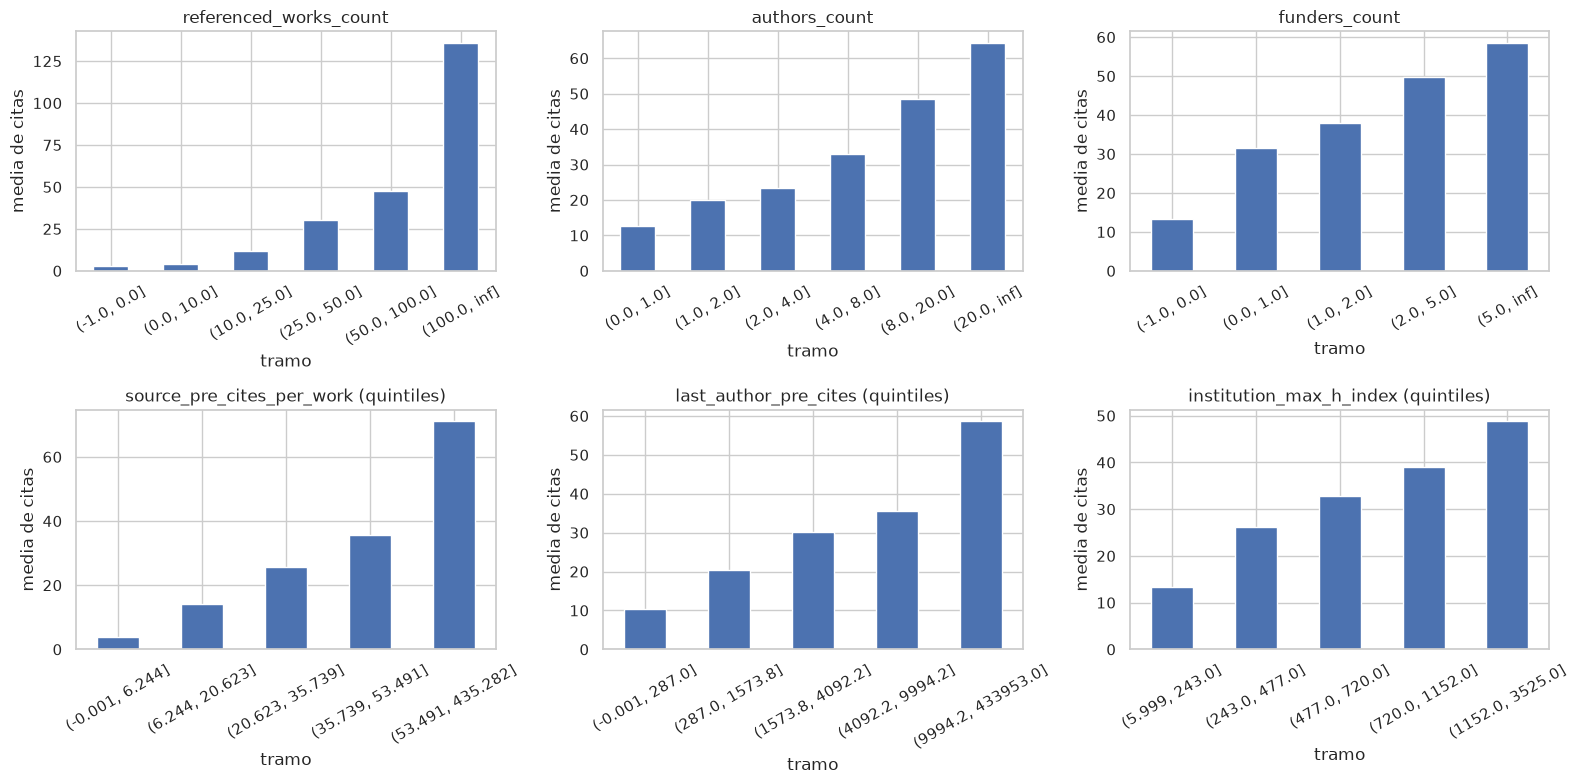

In [16]:
# Medias por tramo: muestran la forma de la relación mejor que un scatter
tramos = {
    "referenced_works_count": [-1, 0, 10, 25, 50, 100, np.inf],
    "authors_count":          [0, 1, 2, 4, 8, 20, np.inf],
    "funders_count":          [-1, 0, 1, 2, 5, np.inf],
}
# Las variables del enriquecimiento no tienen cortes naturales: se usan quintiles
quintiles = ["source_pre_cites_per_work", "last_author_pre_cites", "institution_max_h_index"]

fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for i, (col, cortes) in enumerate(tramos.items()):
    g = df.groupby(pd.cut(df[col], cortes), observed=True)["cited_by_count"].mean()
    g.plot.bar(ax=ax[0, i], color=COLOR, title=col)
for i, col in enumerate(quintiles):
    g = df.groupby(pd.qcut(df[col], 5, duplicates="drop"), observed=True)["cited_by_count"].mean()
    g.plot.bar(ax=ax[1, i], color=COLOR, title=f"{col} (quintiles)")
for a in ax.flat:
    a.set(xlabel="tramo", ylabel="media de citas")
    a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

oa_status,bronze,closed,diamond,gold,green,hybrid
source_is_core,,,,,,
False,3.83,3.98,2.90,6.59,1.12,4.32
True,18.69,34.78,14.48,43.04,42.02,39.96


oa_status,bronze,closed,diamond,gold,green,hybrid
source_is_core,,,,,,
False,168,453,837,61,85,116
True,663,4132,558,1867,870,573


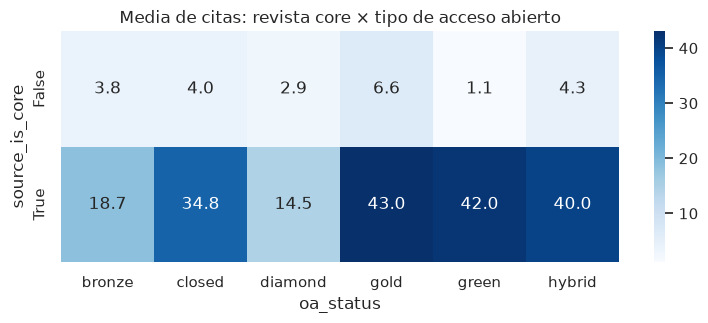

In [17]:
tabla = (df.pivot_table(index="source_is_core", columns="oa_status",
                        values="cited_by_count", aggfunc="mean")
           .round(2))
display(tabla)
display(pd.crosstab(df["source_is_core"], df["oa_status"]))

plt.figure(figsize=(9, 3))
sns.heatmap(tabla, annot=True, fmt=".1f", cmap="Blues")
plt.title("Media de citas: revista core × tipo de acceso abierto"); plt.show()

### Revista core y tipo de acceso

source_is_core indica si la revista donde se publicó el artículo pertenece al conjunto de "fuentes core". Es una lista de revistas que define el CWTS (Centre for Science and Technology Studies) de la Universidad de Leiden, Países Bajos, y que OpenAlex incorpora como atributo de cada revista. Una revista core tiene más visibilidad internacional, y por eso sus artículos reciben más citas. Es un factor de contexto, no una característica del artículo en sí.

Es la variable categórica con mayor contraste: la mediana de citas es 17 en las revistas core y 1 en las no core, el 48,2 % de los artículos de revistas no core no tiene citas (3,9 % en las core) y sólo el 0,3 % llega al top 10 % (14,2 % en las core). Por sí sola explica el 28 % de la varianza de log(1 + citas). Las revistas no core son sobre todo regionales: el primer autor es de Rusia en el 30 % de los casos y el 27 % de los artículos no está en inglés.

Además, se cruza con el tipo de acceso:

- El 90,3 % de los cerrados está en revistas core, contra el 78,8 % de los abiertos.
- El 48,1 % de los artículos de revistas no core son diamond.
- **Dentro de las revistas core, abiertos y cerrados tienen la misma mediana de citas (17).** En las no core, la mediana es 1 para los abiertos y 0 para los cerrados.

La ventaja aparente de los cerrados se debe, entonces, a que los diamond y bronze están concentrados en revistas no core. Si se compara el tipo de acceso sin separar por revista, se mezclan los dos efectos.

Algo parecido pasa con **in_pubmed**: los artículos indexados en PubMed tienen una mediana de 27 citas contra 8, pero el indicador marca sobre todo la revista. Es verdadero en el 37,7 % de los artículos de revistas core y en el 1,1 % de los de revistas no core, y en el 61 % de los de la American Chemical Society.

Los gráficos por tramo muestran que las citas crecen de forma sostenida con las referencias, los financiadores, el prestigio previo de la revista, las citas previas del último autor y el h-index de la institución. En los autores, el crecimiento se detiene a partir de los 8: los artículos con más de 20 autores no tienen más citas que los de 9 a 20.

## 5. Análisis univariado del objetivo

El dataset tiene dos variables objetivo posibles: cited_by_count, la cantidad de citas (numérica), e is_top10_percent, si el artículo está en el 10 % más citado de su campo y año (binaria). Esta sección describe cómo se distribuye cada una, cómo se relacionan entre sí y cómo se acumularon las citas desde 2019.

In [18]:
cit = df["cited_by_count"]
orden = cit.sort_values(ascending=False)
resumen_obj = pd.Series({
    "% con 0 citas":            f"{cit.eq(0).mean():.1%}",
    "mediana":                   cit.median(),
    "media":                     round(cit.mean(), 2),
    "p90":                       cit.quantile(.90),
    "p99":                       cit.quantile(.99),
    "máximo":                    cit.max(),
    "% de citas del top 1 %":    f"{orden.head(int(len(cit) * .01)).sum() / cit.sum():.1%}",
    "% de citas del top 10 %":   f"{orden.head(int(len(cit) * .10)).sum() / cit.sum():.1%}",
    "asimetría":                 round(cit.skew(), 2),
    "asimetría de log(1 + citas)": round(df["log_citas"].skew(), 2),
})
display(resumen_obj.to_frame("cited_by_count"))

,cited_by_count
% con 0 citas,10.5%
mediana,13.0
media,29.84
p90,69.0
p99,260.18
máximo,2625
% de citas del top 1 %,15.7%
% de citas del top 10 %,51.2%
asimetría,11.71
asimetría de log(1 + citas),-0.11


,artículos,proporción
cited_by_count,,
0,1092,0.105
1–4,1801,0.173
5–9,1447,0.139
10–19,2016,0.194
20–49,2424,0.233
50–99,1022,0.098
100+,581,0.056


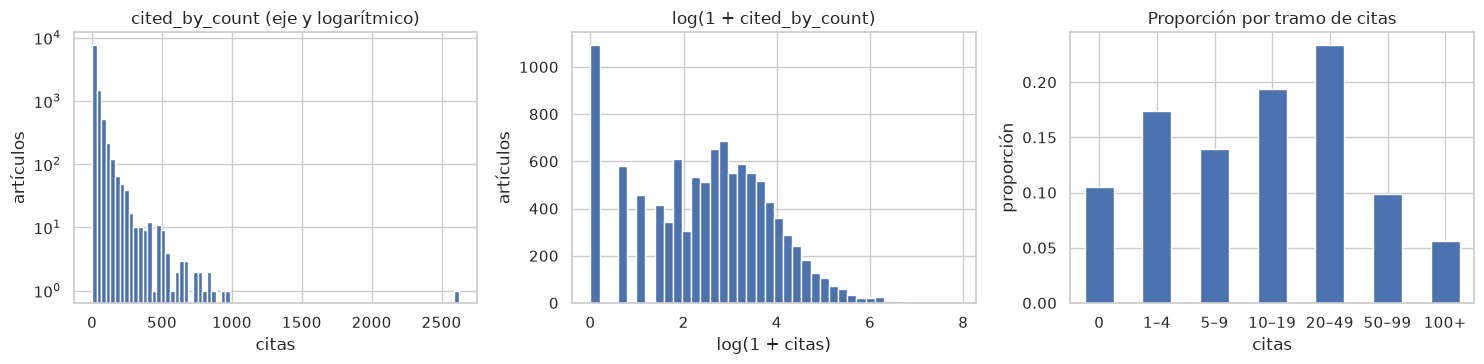

In [19]:
TRAMOS = [-1, 0, 4, 9, 19, 49, 99, np.inf]
ETIQ = ["0", "1–4", "5–9", "10–19", "20–49", "50–99", "100+"]
tramo_citas = pd.cut(cit, TRAMOS, labels=ETIQ)
display(pd.DataFrame({"artículos": tramo_citas.value_counts().sort_index(),
                      "proporción": tramo_citas.value_counts(normalize=True).sort_index().round(3)}))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(cit, bins=80, color=COLOR); axes[0].set_yscale("log")
axes[0].set(title="cited_by_count (eje y logarítmico)", xlabel="citas", ylabel="artículos")
axes[1].hist(df["log_citas"], bins=40, color=COLOR)
axes[1].set(title="log(1 + cited_by_count)", xlabel="log(1 + citas)", ylabel="artículos")
tramo_citas.value_counts(normalize=True).sort_index().plot.bar(ax=axes[2], color=COLOR, rot=0)
axes[2].set(title="Proporción por tramo de citas", xlabel="citas", ylabel="proporción")
plt.tight_layout(); plt.show()

is_top10_percent = True en el 12.0% de la población
Citas de los top 10 %:  mínimo 12  |  mediana 95
Citas del resto:        máximo 133  |  mediana 10
Spearman entre el percentil normalizado y las citas: 0.954


,artículos,% top 10 %
cited_by_count,,
0,1092,0.0
1–4,1801,0.0
5–9,1447,0.0
10–19,2016,0.1
20–49,2424,2.7
50–99,1022,59.2
100+,581,98.6


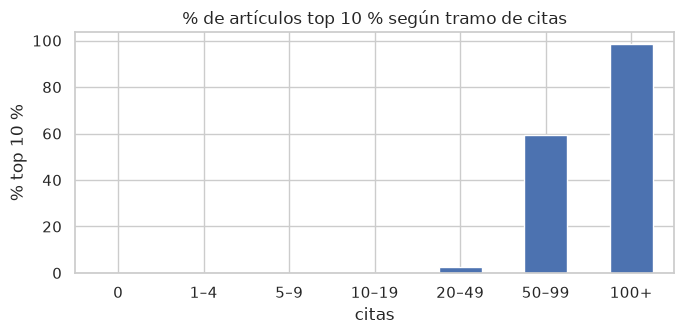

In [20]:
# Relación entre los dos objetivos: is_top10_percent es el percentil normalizado de OpenAlex
top = df["is_top10_percent"]
print(f"is_top10_percent = True en el {top.mean():.1%} de la población")
print(f"Citas de los top 10 %:  mínimo {cit[top].min()}  |  mediana {cit[top].median():.0f}")
print(f"Citas del resto:        máximo {cit[~top].max()}  |  mediana {cit[~top].median():.0f}")
rho_obj = df["citation_normalized_percentile_value"].corr(cit, method="spearman")
print(f"Spearman entre el percentil normalizado y las citas: {rho_obj:.3f}")

pct_top_tramo = top.groupby(tramo_citas, observed=True).mean() * 100
display(pd.DataFrame({"artículos": tramo_citas.value_counts().sort_index(),
                      "% top 10 %": pct_top_tramo.round(1)}))

pct_top_tramo.plot.bar(figsize=(7, 3.5), color=COLOR, rot=0,
                       title="% de artículos top 10 % según tramo de citas",
                       xlabel="citas", ylabel="% top 10 %")
plt.tight_layout(); plt.show()

,citas recibidas,% acumulado
2019,9493,3.1
2020,40725,16.2
2021,50781,32.6
2022,50191,48.9
2023,46924,64.0
2024,45243,78.6
2025,40294,91.7
2026,25809,100.0


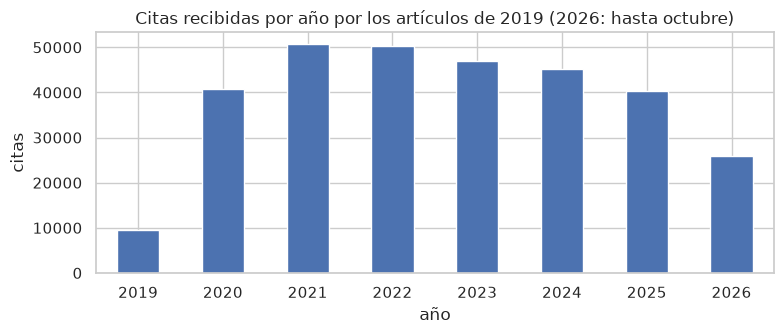

In [21]:
# Trayectoria de las citas: counts_by_year guarda las citas recibidas en cada año
import json
por_anio = pd.DataFrame(
    [{d["year"]: d["cited_by_count"] for d in json.loads(lista)} for lista in df["counts_by_year"]],
    index=df.index).fillna(0)
por_anio = por_anio[sorted(c for c in por_anio.columns if c >= 2019)]

total_anio = por_anio.sum()
acumulado = total_anio.cumsum() / total_anio.sum() * 100
display(pd.DataFrame({"citas recibidas": total_anio.astype(int),
                      "% acumulado": acumulado.round(1)}))

total_anio.plot.bar(figsize=(8, 3.5), color=COLOR, rot=0,
                    title="Citas recibidas por año por los artículos de 2019 (2026: hasta octubre)",
                    xlabel="año", ylabel="citas")
plt.tight_layout(); plt.show()

### Qué muestra el análisis univariado

**1. Distribución de las citas.** Tiene cola larga: la mediana es 13, la media 30,1, el percentil 99 es 279 y el máximo 1.722 (asimetría de 10,57). El 11,0 % de los artículos no tiene citas, y el tramo más poblado es el de 20 a 49 (23,2 %). Las citas están concentradas: el 10 % más citado reúne el 52,1 % del total y el 1 % más citado, el 16,3 %. La concentración es menor que en Medicina 2023, donde esas cifras eran 60,3 % y 24,1 %.

**2. Escala logarítmica.** log(1 + citas) tiene una asimetría de −0,09: es prácticamente simétrica, salvo por el pico de los 1.134 artículos sin citas, que queda separado del resto. Por eso el objetivo numérico del modelo es log(1 + cited_by_count). Ese pico en 0 sugiere que tener o no tener citas puede responder a factores distintos de cuántas se reciben; ya se vio que se concentra en las revistas no core (sección 4).

**3. Relación entre los dos objetivos.** is_top10_percent es verdadero en el 12,0 % de la población. Es más que el 10 % porque OpenAlex calcula el percentil contra todos los trabajos comparables de su base, y la población excluye los registros de repositorios y sin revista, que tienen menos citas (en el dataset completo era el 10,5 %). Los dos objetivos miden casi lo mismo: el percentil normalizado y las citas tienen un Spearman de 0,955. Ningún artículo con menos de 20 citas es top 10 %; lo es el 59,6 % de los que tienen entre 50 y 99 y el 99,0 % de los que tienen 100 o más. Sin embargo, no hay un corte fijo: el artículo top con menos citas tiene 22 y el no top con más citas tiene 194. La normalización de OpenAlex no se puede reproducir con los datos de la muestra, ni por subcampo ni por tema.

**4. Trayectoria de las citas.** Los artículos de 2019 recibieron la mayor cantidad de citas anuales en 2021 y 2022 (unas 50.800 por año), y desde entonces el número baja: 40.334 en 2025. Al cierre de 2022 ya habían recibido el 49 % de las citas que tienen hoy. El objetivo no está cerrado, porque los artículos siguen sumando unas 40.000 citas por año, pero con casi siete años de exposición el máximo del ciclo ya pasó. En Medicina 2023, en cambio, los artículos todavía estaban en la etapa de crecimiento. counts_by_year sirve para describir el objetivo, pero no puede usarse como predictor: son las propias citas.

# Las cuatro hipótesis

Cada hipótesis sigue el mismo esquema: afirmación, qué esperamos ver, cómo se mide, qué se encontró, movimiento y decisión. La medida depende del tipo de variables (dos grupos → separación; varios grupos → η²; dos numéricas → Spearman) y se clasifica con el semáforo de la cátedra:

| Medida | Rojo | Amarillo | Verde |
|---|---|---|---|
| Separación | menos de 0,2 | 0,2 a 0,8 | más de 0,8 |
| η² | menos de 0,05 | 0,05 a 0,25 | más de 0,25 |
| Spearman (valor absoluto) | menos de 0,2 | 0,2 a 0,6 | más de 0,6 |

H1, H2 y H4 son las hipótesis del análisis de Medicina 2023, repetidas sobre la población nueva. H3 cambia de variable: en Medicina se medía con las referencias; acá se usa el prestigio previo de la revista, que en la sección 4 resultó la variable más asociada con las citas.

In [22]:
# ============================================================
# Herramientas de medición y semáforo (las mismas del notebook de la cátedra)
# ============================================================
def separacion(x, y):
    """Distancia entre dos muestras, en desviaciones estándar (valor absoluto)."""
    x, y = x.dropna(), y.dropna()
    return abs(x.mean() - y.mean()) / np.sqrt((x.std() ** 2 + y.std() ** 2) / 2)

def eta2(numerica, categoria):
    """Proporción de la varianza de la numérica que explica la categoría."""
    g = numerica.groupby(categoria)
    m = numerica.mean()
    return (g.count() * (g.mean() - m) ** 2).sum() / ((numerica - m) ** 2).sum()

CORTES = {"separacion": (0.2, 0.8), "eta2": (0.05, 0.25),
          "correlacion": (0.2, 0.6), "brecha": (0.05, 0.15)}

def semaforo(valor, medida):
    """Devuelve la zona en la que cae el valor, según la medida usada."""
    bajo, alto = CORTES[medida]
    v = abs(valor)
    return "rojo" if v < bajo else "verde" if v > alto else "amarillo"

## H1 · Los artículos en acceso abierto reciben más citas *(responder)*

**Afirmación:** los artículos con is_oa = True tienen más citas que los cerrados.

**Qué espero ver:** la literatura habla de una "ventaja de citas del acceso abierto", y en Medicina 2023 la separación fue amarilla (0,311) a favor de los abiertos. Pero la sección 4 mostró que en esta población los cerrados tienen una mediana más alta (14 citas contra 11), así que esperamos una separación chica y en contra de la afirmación.

**Cómo la mido:** dos grupos → separacion sobre log(1 + citas) → histogramas superpuestos y normalizados.

**Qué encontré:** separación **0,188: rojo**, y a favor de los cerrados. La media de log(1 + citas) es 2,382 en los abiertos y 2,646 en los cerrados, con medianas de 11 y 14 citas. El gráfico muestra de dónde sale la diferencia: los abiertos concentran más artículos en el primer tramo, el de cero citas (13,8 % contra 7,6 %). En el resto de la distribución, los dos grupos casi se superponen.

**Movimiento:** ninguno. El rojo termina la hipótesis.

**Qué hago:**
- **La hipótesis se refuta en esta población:** el acceso abierto, tomado en bloque, no da más citas, y los abiertos tienen incluso algo menos.
- **is_oa sale del modelo por redundancia.** Coincide al 100 % con oa_status distinto de "closed" (10.326 de 10.326 filas), y oa_status contiene la misma información con más detalle.
- **Sobre el dominio:** is_oa mezcla tipos de acceso que se comportan al revés. Dentro de las revistas core, gold, green e hybrid tienen medianas de 21 a 23 citas, contra 17 de los cerrados, mientras que bronze y diamond se quedan en 8 y 5. Además, los abiertos están menos en revistas core (78,8 % contra 90,3 %). Sumados, los efectos se compensan. La comparación que tiene sentido es por tipo de acceso, y la mide H2.

**Diferencia con Medicina 2023:** allí el 85 % de los artículos era abierto y los cerrados eran un grupo chico; acá el 45 % es cerrado y el 90 % de los cerrados está en revistas core, que son las más citadas.

In [23]:
# H1 · is_oa vs citas  (comparación de dos grupos → separación sobre log(1 + citas))
abiertos = df.loc[df["is_oa"] == True,  "log_citas"]
cerrados = df.loc[df["is_oa"] == False, "log_citas"]

# Los dos grupos, en números
grupos = pd.DataFrame({
    "n":                  [len(abiertos), len(cerrados)],
    "media log(1+citas)": [abiertos.mean(), cerrados.mean()],
    "mediana citas":      [df.loc[df["is_oa"] == True,  "cited_by_count"].median(),
                           df.loc[df["is_oa"] == False, "cited_by_count"].median()],
    "% sin citas":        [(df.loc[df["is_oa"] == True,  "cited_by_count"] == 0).mean() * 100,
                           (df.loc[df["is_oa"] == False, "cited_by_count"] == 0).mean() * 100],
    "% en revistas core": [df.loc[df["is_oa"] == True,  "source_is_core"].mean() * 100,
                           df.loc[df["is_oa"] == False, "source_is_core"].mean() * 100],
}, index=["abiertos (is_oa=True)", "cerrados (is_oa=False)"]).round(3)
display(grupos)

# Resultado. separacion() devuelve valor absoluto, así que la dirección se lee aparte
sep = separacion(abiertos, cerrados)
dif = abiertos.mean() - cerrados.mean()

display(pd.Series({
    "separación":          round(sep, 3),
    "zona":                semaforo(sep, "separacion"),
    "diferencia de medias (abiertos - cerrados)": round(dif, 3),
    "a favor de":          "abiertos" if dif > 0 else "cerrados",
}).to_frame("H1"))

,n,media log(1+citas),mediana citas,% sin citas,% en revistas core
abiertos (is_oa=True),5798,2.387,11.0,13.556,78.148
cerrados (is_oa=False),4585,2.675,15.0,6.674,90.120


,H1
separación,0.206
zona,amarillo
diferencia de medias (abiertos - cerrados),-0.288
a favor de,cerrados


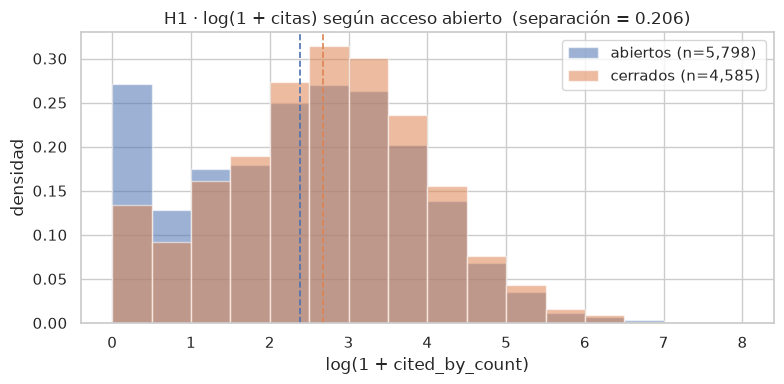

In [24]:
# Gráfico: histogramas superpuestos y normalizados (density=True, porque los grupos son de tamaño distinto)
bins = np.arange(0, df["log_citas"].max() + 0.5, 0.5)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(abiertos, bins=bins, alpha=.55, density=True, label=f"abiertos (n={len(abiertos):,})")
ax.hist(cerrados, bins=bins, alpha=.55, density=True, label=f"cerrados (n={len(cerrados):,})")
ax.axvline(abiertos.mean(), color="C0", ls="--", lw=1.2)
ax.axvline(cerrados.mean(), color="C1", ls="--", lw=1.2)
ax.set(title=f"H1 · log(1 + citas) según acceso abierto  (separación = {sep:.3f})",
       xlabel="log(1 + cited_by_count)", ylabel="densidad")
ax.legend()
plt.tight_layout(); plt.show()

In [25]:
# Chequeo de redundancia: is_oa es una versión más pobre de oa_status
cruce = pd.crosstab(df["oa_status"], df["is_oa"], margins=True)
display(cruce)

deducido = df["oa_status"] != "closed"
coinciden = (df["is_oa"] == deducido).sum()
print(f"is_oa coincide con (oa_status != 'closed') en {coinciden:,} de {len(df):,} filas "
      f"({coinciden / len(df):.1%}).  Filas en desacuerdo: {len(df) - coinciden}")

is_oa,False,True,All
oa_status,,,
bronze,0,831,831
closed,4585,0,4585
diamond,0,1395,1395
gold,0,1928,1928
green,0,955,955
hybrid,0,689,689
All,4585,5798,10383


is_oa coincide con (oa_status != 'closed') en 10,383 de 10,383 filas (100.0%).  Filas en desacuerdo: 0


## H2 · El tipo de acceso abierto explica las citas *(responder)*

**Afirmación:** oa_status explica una parte importante de la variación de log(1 + citas).

**Qué espero ver:** gold, green e hybrid arriba; bronze y diamond abajo, como en Medicina 2023 (η² de 0,199). Sospechamos otra vez que el tipo de revista está detrás: sólo el 40 % de los diamond está en revistas core, contra el 97 % de los gold. Esperamos un η² amarillo.

**Cómo la mido:** seis grupos → eta2 sobre log(1 + citas) → boxplot de log(1 + citas) por oa_status, ordenado por mediana.

**Qué encontré:** η² **0,164: amarillo**. El orden es el esperado: gold (mediana de 21 citas; 1,5 % sin citas), hybrid (18,5) y green (18) arriba; closed (14) en el medio; bronze (5; 23,0 % sin citas) y diamond (2; 34,1 %) abajo. Green vuelve a quedar arriba, como en Medicina, aunque acá no por PubMed Central: son artículos de revistas de suscripción grandes (American Chemical Society, American Physical Society, Wiley) con una copia en un repositorio.

**Movimiento 1: partir la población por tipo de revista (source_is_core).** Los tipos de acceso no se reparten igual entre revistas, y source_is_core es la variable categórica con más contraste de la sección 4. Medimos η² dentro de cada tipo de revista:

| Revistas | Artículos | η² de oa_status | Zona |
|---|---|---|---|
| Todas (sin partir) | 10.326 | 0,164 | amarillo |
| Core | 8.672 | **0,079** | amarillo |
| No core | 1.654 | **0,026** | rojo |
| *Referencia: source_is_core sola* | 10.326 | 0,282 | verde |
| *Referencia: oa_status × source_is_core* | 10.326 | 0,335 | verde |

**Resultado tras el movimiento.** El efecto del acceso **cae a la mitad dentro de las revistas core** (de 0,164 a 0,079; sigue en amarillo, cerca del rojo) y **desaparece en las no core** (0,026, rojo). En las no core, todos los tipos de acceso tienen una mediana de 0 a 3 citas y entre el 21 % y el 72 % de artículos sin citas. Dentro de las core quedan tres bloques: gold, hybrid y green (medianas de 21 a 23 citas, menos del 2 % sin citas), closed (17 citas; 2,9 %) y, abajo, bronze y diamond (8 y 5 citas; 16 % y 14 % sin citas). Gran parte de lo que parecía efecto del acceso era efecto de la revista. No hacemos un segundo movimiento: seguir partiendo sería buscar el subgrupo donde el efecto aparece.

**Veredicto: inconclusa.** oa_status explica una parte moderada de las citas sólo dentro de las revistas core, y menos que en Medicina (0,079 contra 0,127). Fuera de ellas no explica nada.

**Qué hago:**
- **oa_status entra al modelo, siempre junto con source_is_core y nunca sola.** Juntas explican 0,335 (verde) contra 0,282 de source_is_core sola: el acceso agrega unos 5 puntos de varianza explicada. Se codifica con one-hot (seis categorías, todas con más de 600 artículos). Sobre el objetivo binario también separa: el 15,5 % de los gold es top 10 %, contra el 2,2 % de los diamond.
- **is_oa no entra.** Coincide al 100 % con oa_status distinto de "closed" (ver H1).
- **Chequeo de fuga, con advertencia:** gold, diamond, hybrid y closed se conocen al publicar, porque dependen de la revista y del pago. Green y bronze pueden asignarse **después**: el depósito en un repositorio puede tener un embargo, y una editorial puede liberar un artículo más adelante. El oa_status de hoy no es exactamente el que existía al publicar. En la Entrega 3 comparamos el modelo con y sin esas dos categorías.

**Qué quedó abierto:** para separar del todo el efecto del acceso del de la revista haría falta comparar artículos de **la misma revista** con distinto acceso. Sólo hybrid lo permite (abierto contra cerrado dentro de una revista de suscripción), y con 10.326 artículos repartidos en muchas revistas no alcanzan los casos por revista.

,n,media_log,mediana_citas,pct_sin_citas,pct_core,pct_top10
oa_status,,,,,,
gold,1928,3.092,21.5,1.193,96.836,15.975
green,955,2.860,19.0,8.168,91.099,15.393
hybrid,689,2.752,17.0,7.547,83.164,14.369
closed,4585,2.675,15.0,6.674,90.120,13.391
bronze,831,1.887,6.0,21.300,79.783,6.498
diamond,1395,1.209,2.0,32.688,40.000,1.720


,H2
η² (oa_status → log(1+citas)),0.175
zona,amarillo


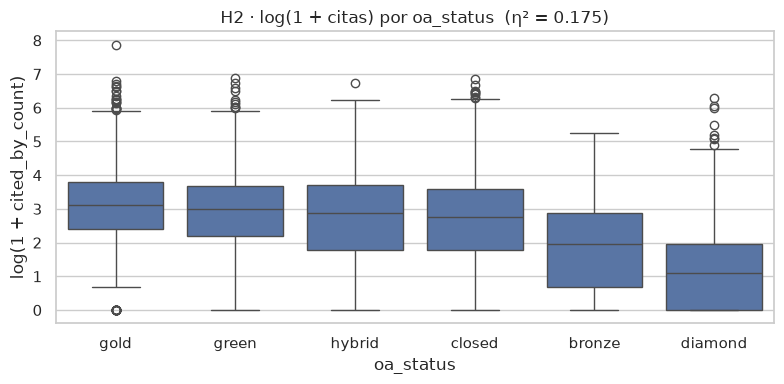

In [26]:
# H2 · oa_status vs citas  (muchos grupos → eta² sobre log(1 + citas))
orden_h2 = (df.groupby("oa_status")["cited_by_count"].median()
              .sort_values(ascending=False).index.tolist())

grupos_h2 = (df.groupby("oa_status")
               .agg(n=("log_citas", "size"),
                    media_log=("log_citas", "mean"),
                    mediana_citas=("cited_by_count", "median"),
                    pct_sin_citas=("cited_by_count", lambda s: (s == 0).mean() * 100),
                    pct_core=("source_is_core", lambda s: s.mean() * 100),
                    pct_top10=("is_top10_percent", lambda s: s.mean() * 100))
               .loc[orden_h2].round(3))
display(grupos_h2)

e2_h2 = eta2(df["log_citas"], df["oa_status"])
display(pd.Series({"η² (oa_status → log(1+citas))": round(e2_h2, 3),
                   "zona": semaforo(e2_h2, "eta2")}).to_frame("H2"))

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df, x="oa_status", y="log_citas", order=orden_h2, color=COLOR, ax=ax)
ax.set(title=f"H2 · log(1 + citas) por oa_status  (η² = {e2_h2:.3f})",
       xlabel="oa_status", ylabel="log(1 + cited_by_count)")
plt.tight_layout(); plt.show()

,artículos,η²,zona
revistas,,,
todas (sin partir),10383,0.175,amarillo
no core,1720,0.035,rojo
core,8663,0.088,amarillo
referencia: source_is_core sola,10383,0.275,verde
referencia: oa_status × source_is_core,10383,0.335,verde


n       mediana       pct_sin_citas      
source_is_core False True    False True          False True 
oa_status                                                   
bronze           168   663     0.5   9.0          50.0  14.0
closed           453  4132     1.0  17.0          41.9   2.8
diamond          837   558     1.0   5.0          44.4  15.1
gold              61  1867     5.0  22.0          13.1   0.8
green             85   870     0.0  22.0          72.9   1.8
hybrid           116   573     1.0  23.0          37.9   1.4

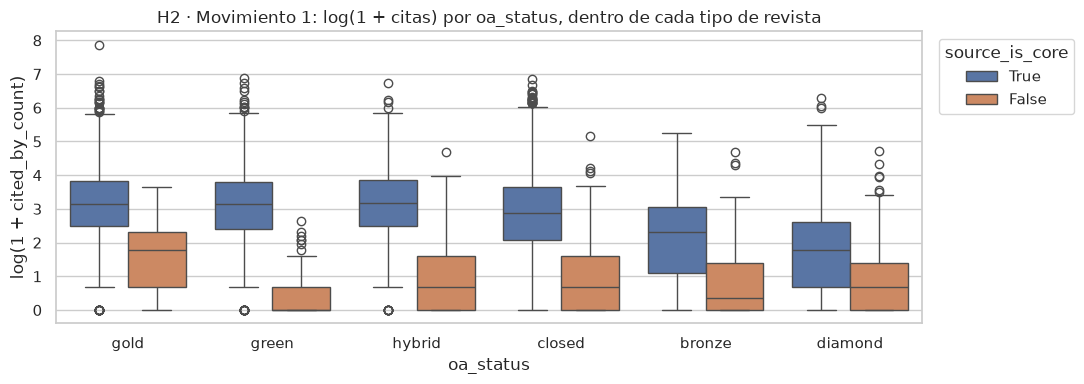

In [27]:
# Movimiento 1 · partir la población por tipo de revista (source_is_core)
filas = []
for core, sub in df.groupby("source_is_core"):
    e = eta2(sub["log_citas"], sub["oa_status"])
    filas.append({"revistas": "core" if core else "no core", "artículos": len(sub),
                  "η²": round(e, 3), "zona": semaforo(e, "eta2")})

e2_core = eta2(df["log_citas"], df["source_is_core"])
filas.append({"revistas": "referencia: source_is_core sola", "artículos": len(df),
              "η²": round(e2_core, 3), "zona": semaforo(e2_core, "eta2")})
e2_combo = eta2(df["log_citas"], df["oa_status"] + "_" + df["source_is_core"].astype(str))
filas.append({"revistas": "referencia: oa_status × source_is_core", "artículos": len(df),
              "η²": round(e2_combo, 3), "zona": semaforo(e2_combo, "eta2")})
filas.insert(0, {"revistas": "todas (sin partir)", "artículos": len(df),
                 "η²": round(e2_h2, 3), "zona": semaforo(e2_h2, "eta2")})
display(pd.DataFrame(filas).set_index("revistas"))

# Medianas y % sin citas de cada tipo de acceso, dentro de cada tipo de revista
display(df.groupby(["source_is_core", "oa_status"])["cited_by_count"]
          .agg(n="size", mediana="median", pct_sin_citas=lambda s: (s == 0).mean() * 100)
          .round(1).unstack(0))

# Gráfico del movimiento: el mismo boxplot, separado por tipo de revista
fig, ax = plt.subplots(figsize=(11, 4))
sns.boxplot(data=df, x="oa_status", y="log_citas", hue="source_is_core",
            order=orden_h2, hue_order=[True, False], ax=ax)
ax.set(title="H2 · Movimiento 1: log(1 + citas) por oa_status, dentro de cada tipo de revista",
       xlabel="oa_status", ylabel="log(1 + cited_by_count)")
ax.legend(title="source_is_core", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.show()

## H3 · El prestigio previo de la revista separa a los artículos top 10 % del resto *(predecir)*

1. **Afirmación:** los artículos con is_top10_percent = True se publican en revistas con más source_pre_cites_per_work (las citas por artículo que recibía la revista entre 2012 y 2018) que el resto.
2. **Qué espero ver:** en la sección 4 fue la variable con mayor Spearman con las citas (0,68). Esperamos una separación verde, cercana a 1, parecida a la que dieron las referencias en Medicina 2023 (1,004).
3. **Cómo la mido:** dos grupos → separacion sobre log(1 + source_pre_cites_per_work) → histogramas superpuestos.
4. **Qué encontré:** **1,261: verde.** La mediana es de 61,5 citas por artículo en las revistas de los top 10 %, contra 26,1 en las del resto. El gráfico muestra que el resto tiene una cola de revistas de bajo prestigio que casi no aparece entre los top: sólo el 1,4 % de los top se publicó en revistas con menos de 10 citas por artículo, contra el 28,2 % del resto. Por quintiles de prestigio, la proporción de top 10 % sube del 0,3 % en el quintil más bajo al 36,9 % en el más alto. Separa más que las referencias (1,013, también verde). **Confirmada.**
5. **Movimiento:** ninguno, porque dio verde. Como chequeo de redundancia, la separación se mantiene dentro de las revistas core (1,117): el prestigio previo no es sólo otra forma de medir source_is_core.
6. **Qué hago:** **source_pre_cites_per_work entra al modelo en escala log.** Con cuatro advertencias:
   - **No es fuga.** Se calcula con las citas que recibió la revista antes de 2019, así que no incluye las del propio artículo, y se conoce al momento de publicar.
   - **Mide la revista, no el artículo.** El modelo aprenderá dónde se publicó el trabajo, que explica una parte grande de su impacto pero no todo.
   - **Faltan 100 artículos (1,0 %)**, cuya revista no tiene historia en OpenAlex entre 2012 y 2018 (en general, revistas nuevas). Se imputan y se marcan con un indicador.
   - **Está correlacionada con referenced_works_count (0,61).** Hay que evaluar si las dos aportan información propia.

,n,sin dato de la revista,media log(1+x),"mediana (citas por artículo, 2012-2018)"
top 10 %,1246,9,4.082,59.960
resto,9137,105,2.920,26.235


,separación,zona
source_pre_cites_per_work (H3),1.205,verde
chequeo: sólo revistas core,1.054,verde
referencia: referenced_works_count,0.982,verde


,% top 10 %
source_pre_cites_per_work,
"(-0.001, 6.244]",0.7
"(6.244, 20.623]",3.2
"(20.623, 35.739]",8.7
"(35.739, 53.491]",13.2
"(53.491, 435.282]",34.5


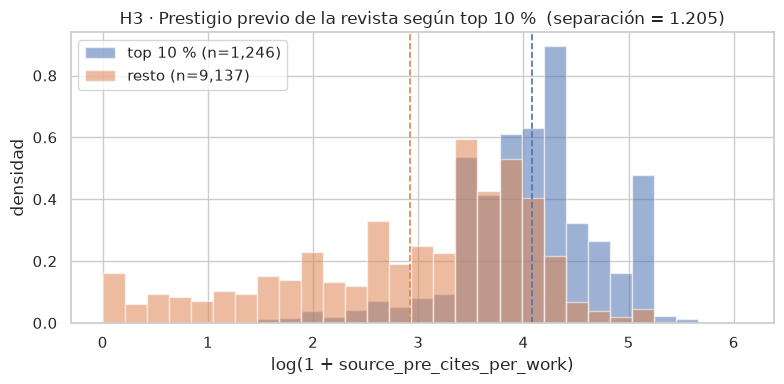

In [28]:
# H3 · prestigio previo de la revista vs top 10 %  (dos grupos → separación sobre log(1 + x))
log_prestigio = np.log1p(df["source_pre_cites_per_work"])
top = df["is_top10_percent"]

grupos_h3 = pd.DataFrame({
    "n":                     [top.sum(), (~top).sum()],
    "sin dato de la revista": [df.loc[top, "source_pre_cites_per_work"].isna().sum(),
                               df.loc[~top, "source_pre_cites_per_work"].isna().sum()],
    "media log(1+x)":         [log_prestigio[top].mean(), log_prestigio[~top].mean()],
    "mediana (citas por artículo, 2012-2018)": [df.loc[top, "source_pre_cites_per_work"].median(),
                                                df.loc[~top, "source_pre_cites_per_work"].median()],
}, index=["top 10 %", "resto"]).round(3)
display(grupos_h3)

sep_h3 = separacion(log_prestigio[top], log_prestigio[~top])
# Referencia: la variable que usaba la H3 en Medicina 2023
sep_refs = separacion(np.log1p(df.loc[top, "referenced_works_count"]),
                      np.log1p(df.loc[~top, "referenced_works_count"]))
# Chequeo de redundancia con source_is_core: la misma separación, sólo en revistas core
en_core = df["source_is_core"]
sep_core = separacion(log_prestigio[top & en_core], log_prestigio[~top & en_core])
display(pd.DataFrame({
    "separación": [round(sep_h3, 3), round(sep_core, 3), round(sep_refs, 3)],
    "zona":       [semaforo(v, "separacion") for v in (sep_h3, sep_core, sep_refs)],
}, index=["source_pre_cites_per_work (H3)", "chequeo: sólo revistas core",
          "referencia: referenced_works_count"]))

# Proporción de top 10 % por quintil de prestigio
display((top.groupby(pd.qcut(df["source_pre_cites_per_work"], 5), observed=True).mean() * 100)
          .round(1).to_frame("% top 10 %"))

bins = np.linspace(0, log_prestigio.max(), 30)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(log_prestigio[top], bins=bins, alpha=.55, density=True, label=f"top 10 % (n={top.sum():,})")
ax.hist(log_prestigio[~top], bins=bins, alpha=.55, density=True, label=f"resto (n={(~top).sum():,})")
ax.axvline(log_prestigio[top].mean(), color="C0", ls="--", lw=1.2)
ax.axvline(log_prestigio[~top].mean(), color="C1", ls="--", lw=1.2)
ax.set(title=f"H3 · Prestigio previo de la revista según top 10 %  (separación = {sep_h3:.3f})",
       xlabel="log(1 + source_pre_cites_per_work)", ylabel="densidad")
ax.legend()
plt.tight_layout(); plt.show()

## H4 · Los artículos publicados a principio de año tienen más citas *(responder)*

**Afirmación:** todos los artículos son de 2019, así que los publicados en enero tuvieron casi un año más que los de diciembre para ser leídos y citados. Por eso deberían tener más citas.

**Qué espero ver:** una relación negativa y chica. En Medicina 2023 dio −0,052 (rojo) con menos de tres años de exposición; con casi siete, once meses de diferencia deberían pesar todavía menos. Esperamos un Spearman cercano a 0.

**Cómo la mido:** dos numéricas → Spearman entre publication_month y cited_by_count (Spearman porque las citas tienen cola larga) → gráfico de la mediana de citas por mes. Se excluyen los 1.646 artículos con la fecha imputada al 1 de enero (sección 2), porque en ellos el mes es desconocido: incluirlos inflaría enero con artículos de cualquier mes. Quedan 8.680.

**Qué encontré:** Spearman **−0,027: rojo**. Con las fechas imputadas da −0,014, también rojo. El signo es el esperado, pero la relación es prácticamente nula. La mediana de citas es algo mayor en enero y febrero (16 y 15) y se mantiene entre 11,5 y 13 el resto del año, sin una bajada sostenida de enero a diciembre.

**Movimiento:** ninguno. El rojo termina la hipótesis.

**Qué hago:**
- **publication_month sale del modelo:** el mes de publicación no ordena las citas.
- **Sobre el dominio:** casi siete años después de publicados, once meses más de exposición no se notan. Pesa mucho más en qué revista se publicó el artículo (H2 y H3).

**Qué quedó abierto:** la exposición seguramente importa en los primeros años y después se diluye. Para verlo habría que comparar por mes las citas recibidas sólo en 2019 y 2020, que están en counts_by_year.

Artículos con fecha real: 8,677 de 10,383
Spearman mes de publicación ~ citas: -0.035  →  rojo
Referencia, incluyendo las fechas imputadas: -0.015


publication_month,1,2,3,4,5,6,7,8,9,10,11,12
mediana de citas,14.0,14.0,14.0,14.0,13.5,13.0,11.0,11.0,13.0,11.0,14.0,12.0


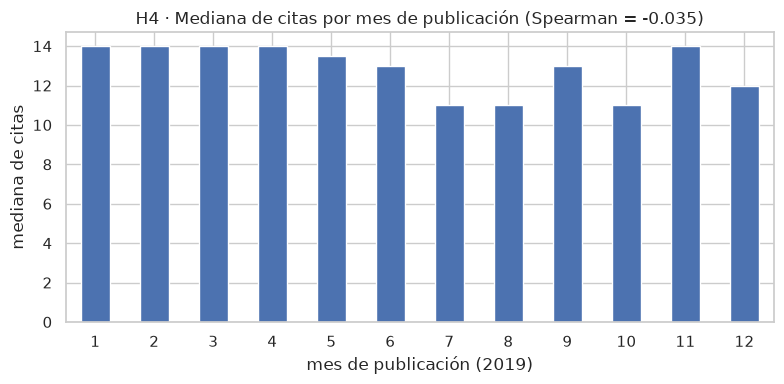

In [29]:
# H4 · Mes de publicación vs citas  (dos numéricas → Spearman)
# Se excluyen las fechas imputadas al 1 de enero: en esos artículos el mes es desconocido
con_fecha = df[~df["fecha_imputada"]]
rho_h4 = con_fecha["publication_month"].corr(con_fecha["cited_by_count"], method="spearman")
rho_todos = df["publication_month"].corr(df["cited_by_count"], method="spearman")
print(f"Artículos con fecha real: {len(con_fecha):,} de {len(df):,}")
print(f"Spearman mes de publicación ~ citas: {rho_h4:.3f}  →  {semaforo(rho_h4, 'correlacion')}")
print(f"Referencia, incluyendo las fechas imputadas: {rho_todos:.3f}")

mediana_por_mes = con_fecha.groupby("publication_month")["cited_by_count"].median()
display(mediana_por_mes.to_frame("mediana de citas").T)
mediana_por_mes.plot.bar(figsize=(8, 4), rot=0, color=COLOR,
                         title=f"H4 · Mediana de citas por mes de publicación (Spearman = {rho_h4:.3f})",
                         xlabel="mes de publicación (2019)", ylabel="mediana de citas")
plt.tight_layout(); plt.show()

# La tabla de columnas candidatas

La tabla reúne la evidencia de cada columna que podría usarse para predecir las citas. Las medidas se calculan en la celda siguiente, con las mismas herramientas de las hipótesis:

- **Numéricas:** Spearman con cited_by_count y separación entre los artículos top 10 % y el resto, sobre log(1 + x).
- **Categóricas y booleanas:** η² sobre log(1 + citas) y brecha, que es la diferencia entre la mayor y la menor proporción de top 10 % entre las categorías con al menos 30 artículos.
- **Mejor zona:** la zona del semáforo de la medida más favorable.

Una columna **entra** si cumple tres condiciones: tiene al menos una medida en amarillo, se conoce al momento de publicar (o parcialmente, con una advertencia) y no repite la información de otra columna que ya entra. Las columnas **en observación** tienen señal, pero gran parte de esa señal pasa por variables que ya entran; se prueban en la Entrega 3. La decisión y su motivo quedan escritos junto a cada columna.

In [30]:
# ============================================================
# Tabla de columnas candidatas: evidencia calculada y decisión
# ============================================================
top = df["is_top10_percent"]

def agrupar(serie, n=15, resto="otras"):
    """Conserva las n categorías más frecuentes y agrupa el resto."""
    serie = serie.fillna("sin dato")
    return serie.where(serie.isin(serie.value_counts().index[:n]), resto)

def brecha(categoria):
    """Diferencia entre la mayor y la menor proporción de top 10 % entre categorías (n >= 30)."""
    g = top.groupby(categoria)
    p = g.mean()[g.size() >= 30]
    return p.max() - p.min()

def zona_maxima(zonas):
    orden = {"rojo": 0, "amarillo": 1, "verde": 2}
    return max(zonas, key=orden.get)

# Numéricas: Spearman con las citas y separación (en log) entre top 10 % y resto
NUMERICAS_CANDIDATAS = [
    "source_pre_cites_per_work", "referenced_works_count", "funders_count", "awards_count",
    "last_author_pre_cites", "last_author_pre_works", "first_author_pre_cites", "first_author_pre_works",
    "institution_max_h_index", "institutions_count", "countries_count", "authors_count",
    "source_pre_works", "source_apc_usd", "abstract_length", "publication_month",
    "corresponding_author_ids_count", "fwci", "citation_normalized_percentile_value",
    "counts_by_year_count", "locations_count", "indexed_in_count", "mesh_count",
]
# Categóricas y booleanas: η² sobre log(1 + citas) y brecha en la proporción de top 10 %
CATEGORICAS_CANDIDATAS = {
    "source_is_core":       df["source_is_core"],
    "oa_status":            df["oa_status"],
    "in_pubmed":            df["in_pubmed"],
    "sin_referencias":      df["sin_referencias"],
    "editorial (15 principales)":    agrupar(df["primary_location_source_host_organization_name"]),
    "first_author_country (15 principales)": agrupar(df["first_author_country"], resto="otros"),
    "language (en / otro)": df["language"].eq("en").map({True: "en", False: "otro"}),
    "apc_paid":             df["apc_paid"],
    "is_oa":                df["is_oa"],
    "is_in_doaj":           df["is_in_doaj"],
    "primary_topic_subfield_display_name": df["primary_topic_subfield_display_name"],
}

filas = []
for c in NUMERICAS_CANDIDATAS:
    x = np.log1p(df[c].clip(lower=0))
    rho = df[c].corr(df["cited_by_count"], method="spearman")
    sep = separacion(x[top], x[~top])
    filas.append({"columna": c, "ρ con citas": rho, "separación top 10 %": sep,
                  "% nulos": df[c].isna().mean() * 100,
                  "mejor zona": zona_maxima([semaforo(rho, "correlacion"), semaforo(sep, "separacion")])})
for c, serie in CATEGORICAS_CANDIDATAS.items():
    e2, br = eta2(df["log_citas"], serie), brecha(serie)
    filas.append({"columna": c, "η²": e2, "brecha top 10 %": br,
                  "% nulos": serie.isna().mean() * 100,
                  "mejor zona": zona_maxima([semaforo(e2, "eta2"), semaforo(br, "brecha")])})
evidencia = pd.DataFrame(filas).set_index("columna")

# Decisión: (qué se hace, transformación, ¿se conoce al publicar?, motivo)
DECISIONES = {
    "source_pre_cites_per_work": ("entra", "log(1 + x) + indicador sin dato", "sí", "La variable más fuerte (H3, verde)"),
    "referenced_works_count":    ("entra", "log(1 + x) + sin_referencias", "sí", "Segunda más fuerte; los ceros son metadatos incompletos"),
    "source_is_core":            ("entra", "booleana", "sí", "Categórica más fuerte; condiciona el efecto del acceso (H2)"),
    "oa_status":                 ("entra", "one-hot, junto con source_is_core", "parcialmente", "Green y bronze pueden asignarse después (H2)"),
    "in_pubmed":                 ("entra", "booleana", "parcialmente", "Agrega información además de la revista y el acceso"),
    "sin_referencias":           ("entra", "booleana", "sí", "Acompaña a referenced_works_count"),
    "funders_count":             ("entra", "log(1 + x)", "sí", "Recursos de la investigación"),
    "last_author_pre_cites":     ("entra", "log(1 + x) + indicador sin dato", "sí", "Trayectoria del jefe de grupo; sólo citas anteriores a 2019"),
    "first_author_pre_cites":    ("entra", "log(1 + x) + indicador sin dato", "sí", "Señal propia, poco correlacionada con la del último autor"),
    "institution_max_h_index":   ("entra", "log(x) + sin_instituciones", "parcialmente", "Es el h-index actual, no el de 2019"),
    "institutions_count":        ("entra", "log(1 + x)", "sí", "Escala de la colaboración"),
    "authors_count":             ("entra", "log(x)", "sí", "Correlacionada con institutions_count, pero por debajo de 0,6"),
    "editorial (15 principales)":            ("en observación", "one-hot (15 + otras)", "sí", "Muy fuerte, pero se superpone con el prestigio y source_is_core"),
    "first_author_country (15 principales)": ("en observación", "one-hot (15 + otros)", "sí", "La mayor parte del efecto pasa por source_is_core"),
    "language (en / otro)":      ("en observación", "booleana", "sí", "Casi todos los artículos no ingleses están en revistas no core"),
    "source_pre_works":          ("en observación", "log(1 + x)", "sí", "Tamaño de la revista; señal débil"),
    "source_apc_usd":            ("en observación", "log(1 + x) + indicador sin dato", "sí", "Señal débil, 42 % de nulos y correlacionada con el prestigio"),
    "fwci":                      ("sale: fuga", "", "no", "Se calcula con las citas"),
    "citation_normalized_percentile_value": ("sale: fuga", "", "no", "Se calcula con las citas"),
    "counts_by_year_count":      ("sale: fuga", "", "no", "Se calcula con las citas"),
    "locations_count":           ("sale: fuga temporal", "", "no", "Crece después de publicar"),
    "indexed_in_count":          ("sale: fuga temporal", "", "no", "Crece después de publicar"),
    "mesh_count":                ("sale: fuga temporal", "", "no", "Se asigna después de publicar"),
    "is_oa":                     ("sale: redundante", "", "sí", "Coincide al 100 % con oa_status != closed (H1)"),
    "apc_paid":                  ("sale: redundante", "", "sí", "No agrega nada a oa_status y source_is_core"),
    "countries_count":           ("sale: redundante", "", "sí", "ρ = 0,66 con institutions_count"),
    "awards_count":              ("sale: redundante", "", "sí", "ρ = 0,81 con funders_count"),
    "last_author_pre_works":     ("sale: redundante", "", "sí", "ρ = 0,89 con last_author_pre_cites"),
    "first_author_pre_works":    ("sale: redundante", "", "sí", "ρ = 0,88 con first_author_pre_cites"),
    "abstract_length":           ("sale: sin asociación", "", "sí", "Rojo en las dos medidas"),
    "publication_month":         ("sale: sin asociación", "", "sí", "Rojo (H4)"),
    "is_in_doaj":                ("sale: sin asociación", "", "sí", "Rojo"),
    "primary_topic_subfield_display_name": ("sale: sin asociación", "", "sí", "η² rojo; la brecha se debe a un subcampo chico"),
    "corresponding_author_ids_count": ("sale: metadatos", "", "sí", "Mide si OpenAlex registró al autor de correspondencia"),
}
tabla_candidatas = evidencia.join(pd.DataFrame(DECISIONES, index=["decisión", "transformación",
                                                                   "conocida al publicar", "motivo"]).T)
orden_decision = ["entra", "en observación", "sale: fuga", "sale: fuga temporal", "sale: redundante",
                  "sale: sin asociación", "sale: metadatos"]
tabla_candidatas["orden"] = tabla_candidatas["decisión"].map(orden_decision.index)
tabla_candidatas["orden_zona"] = tabla_candidatas["mejor zona"].map({"verde": 0, "amarillo": 1, "rojo": 2})
tabla_candidatas = (tabla_candidatas.sort_values(["orden", "orden_zona"]).drop(columns=["orden", "orden_zona"])
                    .round({"ρ con citas": 3, "separación top 10 %": 3, "η²": 3, "brecha top 10 %": 3, "% nulos": 1}))
pd.set_option("display.max_colwidth", 80)
display(tabla_candidatas)

# Variables en observación: cuánto de su efecto queda dentro de las revistas core
en_core = df["source_is_core"]
for c in ["editorial (15 principales)", "first_author_country (15 principales)", "language (en / otro)"]:
    serie = CATEGORICAS_CANDIDATAS[c]
    print(f"η² de {c}: {eta2(df['log_citas'], serie):.3f} en total, "
          f"{eta2(df.loc[en_core, 'log_citas'], serie[en_core]):.3f} dentro de las revistas core")
no_ingles = df["language"] != "en"
print(f"Artículos que no están en inglés publicados en revistas no core: {(~en_core[no_ingles]).mean():.1%}")
print()

# Columnas que repiten a otras: coincidencia exacta fila a fila
for copia, original in [("authorships_count", "authors_count"),
                        ("institutions_distinct_count", "institutions_count"),
                        ("countries_distinct_count", "countries_count")]:
    print(f"{copia} coincide con {original} en el {(df[copia] == df[original]).mean():.1%} de las filas")

# corresponding_*: el cero depende de la revista, no del artículo
for c in ["corresponding_author_ids_count", "corresponding_institution_ids_count"]:
    ceros = (df[c] == 0).groupby(df["source_is_core"]).mean() * 100
    print(f"{c} = 0: {ceros[True]:.1f} % en revistas core, {ceros[False]:.1f} % en no core")
print()

# Referencia para la Entrega 3: cuánto explican juntas las categóricas de la revista
base = df["oa_status"] + "_" + df["source_is_core"].astype(str)
print(f"η² de oa_status × source_is_core:              {eta2(df['log_citas'], base):.3f}")
print(f"η² de oa_status × source_is_core × in_pubmed:  {eta2(df['log_citas'], base + '_' + df['in_pubmed'].astype(str)):.3f}")
print(f"η² de oa_status × source_is_core × apc_paid:   {eta2(df['log_citas'], base + '_' + df['apc_paid'].astype(str)):.3f}")

,ρ con citas,separación top 10 %,% nulos,mejor zona,η²,brecha top 10 %,decisión,transformación,conocida al publicar,motivo
columna,,,,,,,,,,
source_pre_cites_per_work,0.674,1.205,1.1,verde,NaN,NaN,entra,log(1 + x) + indicador sin dato,sí,"La variable más fuerte (H3, verde)"
referenced_works_count,0.643,0.982,0.0,verde,NaN,NaN,entra,log(1 + x) + sin_referencias,sí,Segunda más fuerte; los ceros son metadatos incompletos
source_is_core,NaN,NaN,0.0,verde,0.275,0.135,entra,booleana,sí,Categórica más fuerte; condiciona el efecto del acceso (H2)
funders_count,0.485,0.742,0.0,amarillo,NaN,NaN,entra,log(1 + x),sí,Recursos de la investigación
last_author_pre_cites,0.453,0.767,8.8,amarillo,NaN,NaN,entra,log(1 + x) + indicador sin dato,sí,Trayectoria del jefe de grupo; sólo citas anteriores a 2019
first_author_pre_cites,0.281,0.577,5.0,amarillo,NaN,NaN,entra,log(1 + x) + indicador sin dato,sí,"Señal propia, poco correlacionada con la del último autor"
institution_max_h_index,0.336,0.592,7.1,amarillo,NaN,NaN,entra,log(x) + sin_instituciones,parcialmente,"Es el h-index actual, no el de 2019"
institutions_count,0.326,0.530,0.0,amarillo,NaN,NaN,entra,log(1 + x),sí,Escala de la colaboración
authors_count,0.335,0.487,0.0,amarillo,NaN,NaN,entra,log(x),sí,"Correlacionada con institutions_count, pero por debajo de 0,6"


η² de editorial (15 principales): 0.309 en total, 0.160 dentro de las revistas core
η² de first_author_country (15 principales): 0.204 en total, 0.076 dentro de las revistas core
η² de language (en / otro): 0.097 en total, 0.006 dentro de las revistas core
Artículos que no están en inglés publicados en revistas no core: 93.8%

authorships_count coincide con authors_count en el 100.0% de las filas
institutions_distinct_count coincide con institutions_count en el 100.0% de las filas
countries_distinct_count coincide con countries_count en el 99.9% de las filas
corresponding_author_ids_count = 0: 22.0 % en revistas core, 66.4 % en no core
corresponding_institution_ids_count = 0: 15.8 % en revistas core, 53.4 % en no core

η² de oa_status × source_is_core:              0.335
η² de oa_status × source_is_core × in_pubmed:  0.381
η² de oa_status × source_is_core × apc_paid:   0.336


## Conclusión: columnas que se conservan para predecir la cantidad de citas

**Objetivo del modelo:** log(1 + cited_by_count). Las citas tienen una asimetría de 10,57 que baja a −0,09 en escala logarítmica: la mediana es 13, la media 30,1, el 11,0 % de los artículos no tiene citas y el 1 % más citado concentra el 16,3 % del total. El objetivo binario, is_top10_percent (12,0 % de la población), mide casi lo mismo (Spearman de 0,955 entre el percentil y las citas) y queda como alternativa.

### Columnas que entran (12)

| Columna | Evidencia | Transformación | Observación |
|---|---|---|---|
| source_pre_cites_per_work | ρ = 0,68 · separación 1,26 (verde, H3) | log(1 + x) + indicador sin dato | La variable más fuerte. Mide la revista, no el artículo. Falta en el 1,0 % (revistas sin historia entre 2012 y 2018). |
| referenced_works_count | ρ = 0,65 · separación 1,01 (verde) | log(1 + x) + sin_referencias | ρ = 0,61 con el prestigio de la revista. Los ceros (10,4 %) son metadatos incompletos. |
| source_is_core | η² = 0,282 (verde) | booleana | La categórica más fuerte. Condiciona el efecto del acceso abierto (H2). |
| oa_status | η² = 0,164 → 0,335 junto con source_is_core (H2) | one-hot | Entra siempre junto con source_is_core. Green y bronze pueden asignarse después de publicar: en la Entrega 3 se compara el modelo con y sin esas dos categorías. |
| in_pubmed | η² = 0,161; sube la combinación anterior de 0,335 a 0,384 | booleana | Marca sobre todo la revista (37,7 % de los artículos core contra 1,1 % de los no core). Parcialmente conocida al publicar. |
| sin_referencias | η² = 0,199 | booleana | Acompaña a referenced_works_count. |
| funders_count | ρ = 0,48 · separación 0,78 | log(1 + x) | Indica cuántos recursos tuvo la investigación. |
| last_author_pre_cites | ρ = 0,43 · separación 0,72 | log(1 + x) + indicador sin dato | Trayectoria del jefe de grupo, sólo con citas anteriores a 2019. |
| first_author_pre_cites | ρ = 0,26 · separación 0,51 | log(1 + x) + indicador sin dato | ρ = 0,30 con la del último autor: aporta información propia. |
| institution_max_h_index | ρ = 0,32 · separación 0,53 | log(x) + sin_instituciones | Es el h-index actual de la institución, no el de 2019: parcialmente conocido al publicar. |
| institutions_count | ρ = 0,32 · separación 0,52 | log(1 + x) | Resume la escala de la colaboración. |
| authors_count | ρ = 0,33 · separación 0,55 | log(x) | Correlacionada con institutions_count (0,52), pero por debajo de 0,6. |

### En observación (5)

Tienen señal, pero gran parte pasa por la revista. Entran en una segunda versión del modelo y se descartan si no mejoran el error:

- **Editorial** (15 principales + otras): η² = 0,322 (verde), pero baja a 0,169 dentro de las revistas core y se superpone con el prestigio de la revista.
- **País del primer autor** (15 principales + otros): η² = 0,199, que baja a 0,072 dentro de las revistas core.
- **Idioma** (en / otro): η² = 0,102, que baja a 0,002 dentro de las revistas core. El 95,1 % de los artículos que no están en inglés se publicó en revistas no core, así que el idioma casi no agrega información a source_is_core.
- **source_pre_works**: ρ = 0,29. Mide el tamaño de la revista, no su prestigio.
- **source_apc_usd**: ρ = 0,27, con 42,2 % de nulos y correlacionada con el prestigio de la revista (0,52).

### Columnas que salen

- **Fuga (se calculan con las citas, que son lo que se quiere predecir):** fwci, citation_normalized_percentile_value y counts_by_year_count, además del otro objetivo, is_top10_percent.
- **Fuga temporal (crecen después de publicar):** locations_count, indexed_in_count y mesh_count. Están asociadas a las citas (ρ entre 0,20 y 0,39), pero en parte son una consecuencia de ellas y no una causa.
- **Redundantes:** is_oa (coincide al 100 % con oa_status distinto de "closed"), apc_paid (no agrega nada a oa_status y source_is_core: 0,335 contra 0,336), countries_count (ρ = 0,66 con institutions_count), awards_count (ρ = 0,81 con funders_count), first_author_pre_works y last_author_pre_works (ρ de 0,88 y 0,89 con las citas previas de cada autor), y authorships_count, institutions_distinct_count y countries_distinct_count, que son copias de los conteos de autores, instituciones y países.
- **Sin asociación:** abstract_length (ρ = 0,15 y separación 0,04), publication_month (H4), is_in_doaj (η² = 0,011) y el subcampo (η² = 0,021).
- **Metadatos de OpenAlex:** corresponding_author_ids_count y corresponding_institution_ids_count. Valen 0 en el 66 % y el 54 % de los artículos de revistas no core, contra el 22 % y el 16 % de las core: miden si OpenAlex registró al autor de correspondencia, no una característica del trabajo.
- **Constantes por los filtros de la población:** se descartaron en la sección 2.

### Síntesis

Las citas de un artículo de Ciencia de Materiales dependen sobre todo de **dos dimensiones**, como en Medicina:

1. **Dónde se publica:** el prestigio previo de la revista, si es core, el tipo de acceso y si está indexada en PubMed.
2. **La escala y la trayectoria del trabajo:** las referencias, los financiadores, la trayectoria del último autor, las instituciones y los autores.

Respecto de Medicina 2023 cambian tres cosas: el acceso abierto tomado en bloque no da ventaja (H1), la revista pesa todavía más y ahora se mide directamente con su prestigio previo (H3), y el momento de publicación dentro del año sigue sin influir (H4). Juntas, oa_status, source_is_core e in_pubmed explican el 38,4 % de la varianza de log(1 + citas). Esa cifra es la referencia que el modelo de la Entrega 3 tiene que superar cuando se sumen las variables numéricas.